<a href="https://colab.research.google.com/github/Yisihaq01/breast-histology-calibration/blob/main/Notebooks/09_efficientnet_b0_controlled_distribution_shifts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Stage 9 — Controlled Distribution Shift Evaluation

## Objective

Evaluate the effects of controlled color, blur, and noise
perturbations on discrimination and probability calibration
of the final frozen EfficientNet-B0 classifier.

## Evaluation cohort

- Dataset: BreaKHis
- Partition: Independent Test
- Magnification: 40x
- Patients: 16
- Images: 446
- Patches: 7,087

## Experimental conditions

One clean reference condition and nine shifted conditions:

1. Stain-like optical-density color shift: low, medium, high
2. Gaussian blur: low, medium, high
3. Gaussian noise: low, medium, high

The color perturbation is a stain-like proxy rather than
a validated H&E stain transformation.

## Locked methodology

- Final EfficientNet-B0 Epoch 5 checkpoint
- Original 224x224 patch preprocessing
- Original tissue-selected patch coordinates
- Original image-level mean-logit aggregation
- Frozen temperature scaling
- Frozen Platt scaling
- No model training or calibration refitting

All shifts will be applied after the original patch
selection and before ImageNet input normalization.

Noise will be generated deterministically with fixed seeds.

## Evaluation

Each condition will be evaluated using:

- AUROC
- Average precision
- Balanced accuracy
- ECE (10 bins)
- Brier score
- Negative log-likelihood

Paired patient-level bootstrap resampling will be used to
compare shifted performance against the clean reference.

## Interpretation

This is a secondary exploratory sensitivity analysis on
the previously evaluated independent Test patients.

Shift severity is fixed before inspecting shifted predictions.
No Test-based tuning or model selection is permitted.


In [ ]:

# ============================================================
# Environment, Stage 8 Provenance, and Shift Protocol Lock
# ============================================================

import io
import json
import hashlib
import zipfile
import subprocess

from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
import torch

from google.colab import files

# ------------------------------------------------------------
# 1. Locate or clone research repository
# ------------------------------------------------------------

REPO_ROOT = Path(
    "/content/breast-histology-calibration"
)

REPO_URL = (
    "https://github.com/Yisihaq01/"
    "breast-histology-calibration.git"
)

if not (REPO_ROOT / ".git").is_dir():

    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_ROOT)],
        check=True
    )

    print("Repository cloned.")

else:
    print("Existing repository located.")

assert (REPO_ROOT / ".git").is_dir()

assert torch.cuda.is_available(), (
    "Please enable the T4 GPU runtime."
)

DEVICE = torch.device("cuda")

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


git_commit = subprocess.check_output(
    [
        "git",
        "-C",
        str(REPO_ROOT),
        "rev-parse",
        "--short",
        "HEAD"
    ],
    text=True
).strip()

print("\n" + "=" * 70)
print("STAGE 9 — ENVIRONMENT")
print("=" * 70)

print("Repository:", REPO_ROOT)
print("Commit:", git_commit)
print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 2. Restore Stage 8 result package if needed
# ------------------------------------------------------------

STAGE8_RESULTS_DIR = (
    REPO_ROOT /
    "results/independent_test/efficientnet_b0"
)

STAGE8_INVENTORY_PATH = (
    STAGE8_RESULTS_DIR /
    "stage8_package_file_inventory.csv"
)

if not STAGE8_INVENTORY_PATH.is_file():

    backup_zip = Path(
        "/content/"
        "CIS631_Stage8_Complete_Results_For_GitHub.zip"
    )

    if not backup_zip.is_file():

        print("\nStage 8 results package not found.")
        print("Upload the completed Stage 8 results ZIP.")

        uploaded = files.upload()

        assert len(uploaded) == 1, (
            "Upload exactly one Stage 8 results ZIP."
        )

        uploaded_name, uploaded_bytes = next(
            iter(uploaded.items())
        )

        assert uploaded_name == backup_zip.name, (
            "Incorrect backup selected."
        )

        backup_zip.write_bytes(uploaded_bytes)

    with zipfile.ZipFile(backup_zip) as archive:

        assert archive.testzip() is None

        names = archive.namelist()

        assert len(names) == 33
        assert len(set(names)) == 33

        inventory_name = str(
            STAGE8_INVENTORY_PATH.relative_to(REPO_ROOT)
        )

        assert inventory_name in names

        inventory_from_zip = pd.read_csv(
            io.BytesIO(archive.read(inventory_name))
        )

        assert len(inventory_from_zip) == 32

        expected_names = set(
            inventory_from_zip["relative_path"].tolist()
        ) | {inventory_name}

        assert set(names) == expected_names

        for name in names:

            relative = PurePosixPath(name)

            assert not relative.is_absolute()
            assert ".." not in relative.parts

            assert (
                name.startswith("Metadata/")
                or name.startswith(
                    "results/independent_test/efficientnet_b0/"
                )
            )

        # Verify all archived file hashes before restoring.

        for _, row in inventory_from_zip.iterrows():

            content = archive.read(row["relative_path"])

            actual_hash = hashlib.sha256(
                content
            ).hexdigest()

            assert actual_hash == row["sha256"]

        # Restore only validated files.
        # Existing conflicting files are never overwritten.

        for name in names:

            destination = REPO_ROOT / name

            destination.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            content = archive.read(name)

            if destination.exists():

                assert destination.read_bytes() == content, (
                    f"Existing file differs: {name}"
                )

            else:

                destination.write_bytes(content)

    print("PASS: Stage 8 results ZIP restored.")

else:

    print("Stage 8 results inventory located.")

# ------------------------------------------------------------
# 3. Verify all 32 inventoried Stage 8 files
# ------------------------------------------------------------

assert STAGE8_INVENTORY_PATH.is_file()

stage8_inventory = pd.read_csv(
    STAGE8_INVENTORY_PATH
)

assert len(stage8_inventory) == 32

for _, row in stage8_inventory.iterrows():

    relative = PurePosixPath(row["relative_path"])

    assert not relative.is_absolute()
    assert ".." not in relative.parts

    path = REPO_ROOT / row["relative_path"]

    assert path.is_file(), (
        f"Missing Stage 8 file: {path}"
    )

    assert sha256_file(path) == row["sha256"], (
        f"Stage 8 integrity mismatch: {path}"
    )

print("PASS: All 32 inventoried Stage 8 files verified.")

# ------------------------------------------------------------
# 4. Verify final model and calibration provenance
# ------------------------------------------------------------

EXPECTED_MODEL_SHA256 = (
    "84ea0871a309f3d68b8958b68b6da4f01adb31d3109fa4e0fc57f6670b63c9bb"
)

STAGE7_RESULTS_DIR = (
    REPO_ROOT /
    "results/posthoc_calibration/efficientnet_b0"
)

LOCK_PATH = (
    STAGE7_RESULTS_DIR /
    "calibration_lock_record.json"
)

PARAMETERS_PATH = (
    STAGE7_RESULTS_DIR /
    "calibration_fitted_parameters.json"
)

assert LOCK_PATH.is_file()
assert PARAMETERS_PATH.is_file()

with open(LOCK_PATH, encoding="utf-8") as f:
    calibration_lock = json.load(f)

with open(PARAMETERS_PATH, encoding="utf-8") as f:
    calibration_parameters = json.load(f)

assert calibration_lock["status"] == (
    "completed_and_locked"
)

assert calibration_lock[
    "final_checkpoint_sha256"
] == EXPECTED_MODEL_SHA256

assert calibration_lock[
    "calibration_parameters_sha256"
] == sha256_file(PARAMETERS_PATH)

LOCKED_TEMPERATURE = float(
    calibration_parameters[
        "temperature_scaling"
    ]["temperature"]
)

LOCKED_PLATT_SLOPE = float(
    calibration_parameters[
        "platt_scaling"
    ]["slope"]
)

LOCKED_PLATT_INTERCEPT = float(
    calibration_parameters[
        "platt_scaling"
    ]["intercept"]
)

assert np.isclose(
    LOCKED_TEMPERATURE,
    4.069193139210192,
    rtol=0,
    atol=1e-12
)

assert np.isclose(
    LOCKED_PLATT_SLOPE,
    0.29141657172422586,
    rtol=0,
    atol=1e-12
)

assert np.isclose(
    LOCKED_PLATT_INTERCEPT,
    -0.7096590060187311,
    rtol=0,
    atol=1e-12
)

print("PASS: Final CNN checkpoint identity verified.")
print("PASS: Both locked calibrators verified.")

# ------------------------------------------------------------
# 5. Load and verify original 40x Test reference
# ------------------------------------------------------------

TEST40_MANIFEST_PATH = (
    REPO_ROOT /
    "Metadata/breakhis_test_40x_patch_manifest.csv"
)

TEST40_PREDICTIONS_PATH = (
    STAGE8_RESULTS_DIR /
    "test_40x_image_predictions.csv"
)

TEST40_INFERENCE_AUDIT_PATH = (
    STAGE8_RESULTS_DIR /
    "test_40x_inference_audit.json"
)

TEST_MANIFEST_AUDIT_PATH = (
    STAGE8_RESULTS_DIR /
    "test_patch_manifest_audit.json"
)

assert all(
    path.is_file()
    for path in [
        TEST40_MANIFEST_PATH,
        TEST40_PREDICTIONS_PATH,
        TEST40_INFERENCE_AUDIT_PATH,
        TEST_MANIFEST_AUDIT_PATH
    ]
)

with open(
    TEST40_INFERENCE_AUDIT_PATH,
    encoding="utf-8"
) as f:
    test40_inference_audit = json.load(f)

with open(
    TEST_MANIFEST_AUDIT_PATH,
    encoding="utf-8"
) as f:
    test_manifest_audit = json.load(f)

assert sha256_file(
    TEST40_MANIFEST_PATH
) == test40_inference_audit[
    "input_manifest_sha256"
]

assert sha256_file(
    TEST40_PREDICTIONS_PATH
) == test40_inference_audit[
    "image_predictions_sha256"
]

assert test40_inference_audit[
    "checkpoint_sha256"
] == EXPECTED_MODEL_SHA256

assert test40_inference_audit[
    "aggregation"
] == "mean_patch_logit"

test40_manifest = pd.read_csv(
    TEST40_MANIFEST_PATH,
    dtype={"patient_id": str}
)

test40_predictions = pd.read_csv(
    TEST40_PREDICTIONS_PATH,
    dtype={
        "patient_id": str,
        "filename": str
    }
)

assert len(test40_manifest) == 7087
assert len(test40_predictions) == 446

assert test40_manifest["filename"].nunique() == 446

assert test40_predictions["filename"].is_unique

assert test40_manifest["patient_id"].nunique() == 16

assert test40_predictions["patient_id"].nunique() == 16

assert set(test40_manifest["filename"]) == set(
    test40_predictions["filename"]
)

assert set(test40_manifest["patient_id"]) == set(
    test40_predictions["patient_id"]
)

assert (
    test40_predictions["n_patches"].sum()
) == 7087

assert (
    test40_predictions.groupby("patient_id")[
        "label"
    ].nunique().max()
) == 1

patient_labels = (
    test40_predictions
    .groupby("patient_id")["label"]
    .first()
)

assert int((patient_labels == 0).sum()) == 5
assert int((patient_labels == 1).sum()) == 11

print("PASS: Original 40x Test reference verified.")
print("PASS: 446 Test images and 7,087 patches verified.")
print("PASS: All 16 independent Test patients verified.")

# ------------------------------------------------------------
# 6. LOCK Stage 9 experimental conditions
#
# These values are fixed before shifted inference.
# ------------------------------------------------------------

STAGE9_SEED = 631

STAIN_LIKE_OD_LEVELS = {
    "low": 0.05,
    "medium": 0.10,
    "high": 0.20
}

BLUR_SIGMA_LEVELS = {
    "low": 0.5,
    "medium": 1.0,
    "high": 2.0
}

NOISE_SIGMA_LEVELS = {
    "low": 0.02,
    "medium": 0.05,
    "high": 0.10
}

STAGE9_RESULTS_DIR = (
    REPO_ROOT /
    "results/controlled_shifts/efficientnet_b0"
)

STAGE9_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

stage9_protocol = {
    "stage": 9,
    "status": "pre_inference_protocol_locked",

    "test_magnification": 40,
    "test_patients": 16,
    "test_images": 446,
    "patches_per_condition": 7087,

    "conditions": {
        "clean": {"severity": "none"},
        "stain_like_od": STAIN_LIKE_OD_LEVELS,
        "gaussian_blur": BLUR_SIGMA_LEVELS,
        "gaussian_noise": NOISE_SIGMA_LEVELS
    },

    "n_conditions": 10,

    "perturbation_unit": "original_tissue_selected_patch",

    "perturbation_stage":
        "after_original_patch_extraction_before_normalization",

    "original_patch_coordinates_preserved": True,
    "original_tissue_selection_preserved": True,

    "color_shift_method":
        "controlled_rgb_optical_density_channel_scaling",

    "color_shift_is_validated_he_stain_transform": False,

    "blur_method": "gaussian_blur",

    "noise_method": "additive_rgb_gaussian_noise",

    "noise_sigma_units": "rgb_fraction_0_to_1",

    "noise_seed": STAGE9_SEED,

    "aggregation": "mean_patch_logit",

    "calibration_methods": [
        "uncalibrated",
        "temperature_scaling",
        "platt_scaling"
    ],

    "bootstrap_resamples": 1000,
    "bootstrap_sampling_unit": "patient_id",

    "analysis_type":
        "secondary_exploratory_test_sensitivity",

    "model_checkpoint_sha256":
        EXPECTED_MODEL_SHA256,

    "calibration_parameters_sha256":
        sha256_file(PARAMETERS_PATH),

    "clean_test_manifest_sha256":
        sha256_file(TEST40_MANIFEST_PATH),

    "clean_test_predictions_sha256":
        sha256_file(TEST40_PREDICTIONS_PATH),

    "cnn_retraining_allowed": False,
    "calibrator_refitting_allowed": False,
    "test_based_severity_tuning_allowed": False
}

STAGE9_PROTOCOL_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_pre_inference_protocol_lock.json"
)

# Existing protocol must match exactly.
# Do not silently replace a previously locked protocol.

if STAGE9_PROTOCOL_PATH.is_file():

    with open(
        STAGE9_PROTOCOL_PATH,
        encoding="utf-8"
    ) as f:
        existing_protocol = json.load(f)

    assert existing_protocol == stage9_protocol, (
        "Existing Stage 9 protocol differs. "
        "Do not change the locked experiment."
    )

    print("Existing Stage 9 protocol verified.")

else:

    with open(
        STAGE9_PROTOCOL_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            stage9_protocol,
            f,
            indent=2
        )

    print("Stage 9 protocol created and locked.")

# ------------------------------------------------------------
# 7. Final readiness summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STAGE 9 — CONTROLLED SHIFT EXPERIMENT DESIGN")
print("=" * 70)

print("Test patients: 16")
print("Clean Test images: 446")
print("Patches per condition: 7,087")
print("Clean conditions: 1")
print("Shifted conditions: 9")
print("Total conditions: 10")

print("\nStain-like OD levels:", STAIN_LIKE_OD_LEVELS)
print("Blur sigma levels:", BLUR_SIGMA_LEVELS)
print("Noise sigma levels:", NOISE_SIGMA_LEVELS)

print("\nLocked temperature:", LOCKED_TEMPERATURE)
print("Locked Platt slope:", LOCKED_PLATT_SLOPE)
print("Locked Platt intercept:", LOCKED_PLATT_INTERCEPT)

print("\n" + "=" * 70)
print("STAGE 9 — CELL 2 FINAL AUDIT")
print("=" * 70)

print("PASS: Research repository verified.")
print("PASS: Stage 8 results package verified.")
print("PASS: Final CNN provenance verified.")
print("PASS: Calibration lock verified.")
print("PASS: Original 40x Test manifest verified.")
print("PASS: Original clean Test predictions verified.")
print("PASS: 16 independent Test patients verified.")
print("PASS: 7,087 original selected patches verified.")
print("PASS: Three shift families specified.")
print("PASS: Three severity levels per family specified.")
print("PASS: Original patch selection will be preserved.")
print("PASS: Deterministic noise seed specified.")
print("PASS: Stage 9 experimental protocol locked.")
print("PASS: No model inference performed.")
print("PASS: No retraining or recalibration.")

print("\nProtocol:", STAGE9_PROTOCOL_PATH)
print("Protocol SHA-256:", sha256_file(STAGE9_PROTOCOL_PATH))


Repository cloned.

STAGE 9 — ENVIRONMENT
Repository: /content/breast-histology-calibration
Commit: b7e607e
Device: cuda
GPU: Tesla T4
Stage 8 results inventory located.
PASS: All 32 inventoried Stage 8 files verified.
PASS: Final CNN checkpoint identity verified.
PASS: Both locked calibrators verified.
PASS: Original 40x Test reference verified.
PASS: 446 Test images and 7,087 patches verified.
PASS: All 16 independent Test patients verified.
Stage 9 protocol created and locked.

STAGE 9 — CONTROLLED SHIFT EXPERIMENT DESIGN
Test patients: 16
Clean Test images: 446
Patches per condition: 7,087
Clean conditions: 1
Shifted conditions: 9
Total conditions: 10

Stain-like OD levels: {'low': 0.05, 'medium': 0.1, 'high': 0.2}
Blur sigma levels: {'low': 0.5, 'medium': 1.0, 'high': 2.0}
Noise sigma levels: {'low': 0.02, 'medium': 0.05, 'high': 0.1}

Locked temperature: 4.069193139210192
Locked Platt slope: 0.29141657172422586
Locked Platt intercept: -0.7096590060187311

STAGE 9 — CELL 2 FINAL A

PASS: Stage 9 experimental protocol verified.
PASS: Original patch preprocessing restored.
PASS: All eight preprocessing constants verified.
Using Colab cache for faster access to the 'breakhis' dataset.
Dataset root: /kaggle/input/breakhis
PASS: All 446 original Test images located.
PASS: Ten experimental conditions established.
PASS: Stain-like OD perturbation implemented.
PASS: Gaussian blur implemented.
PASS: Deterministic Gaussian noise implemented.
PASS: Benign patch reconstruction matches original extraction.
PASS: Malignant patch reconstruction matches original extraction.


/tmp/ipykernel_578/3252629307.py:370: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  result = Image.fromarray(


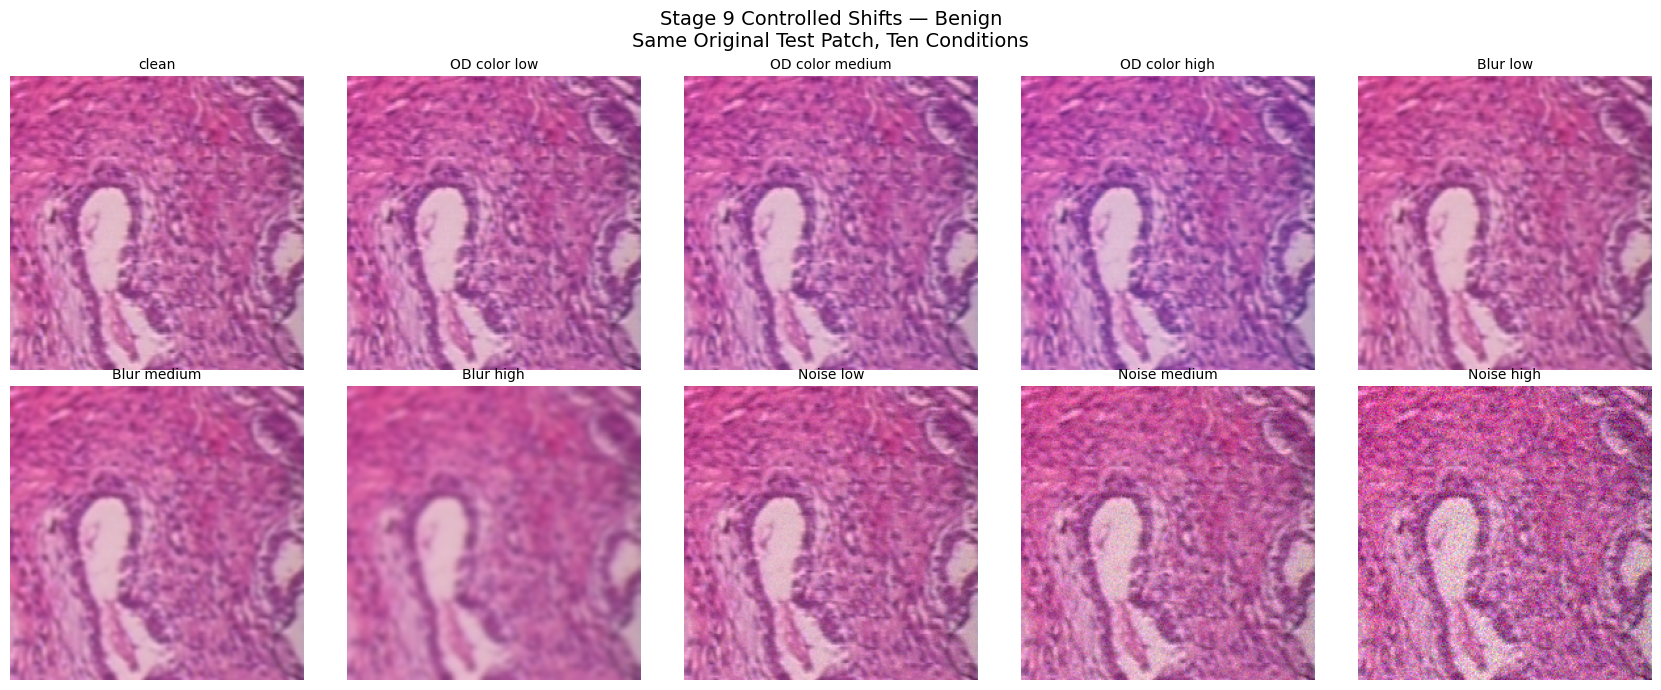

PASS: Benign shift preview saved.


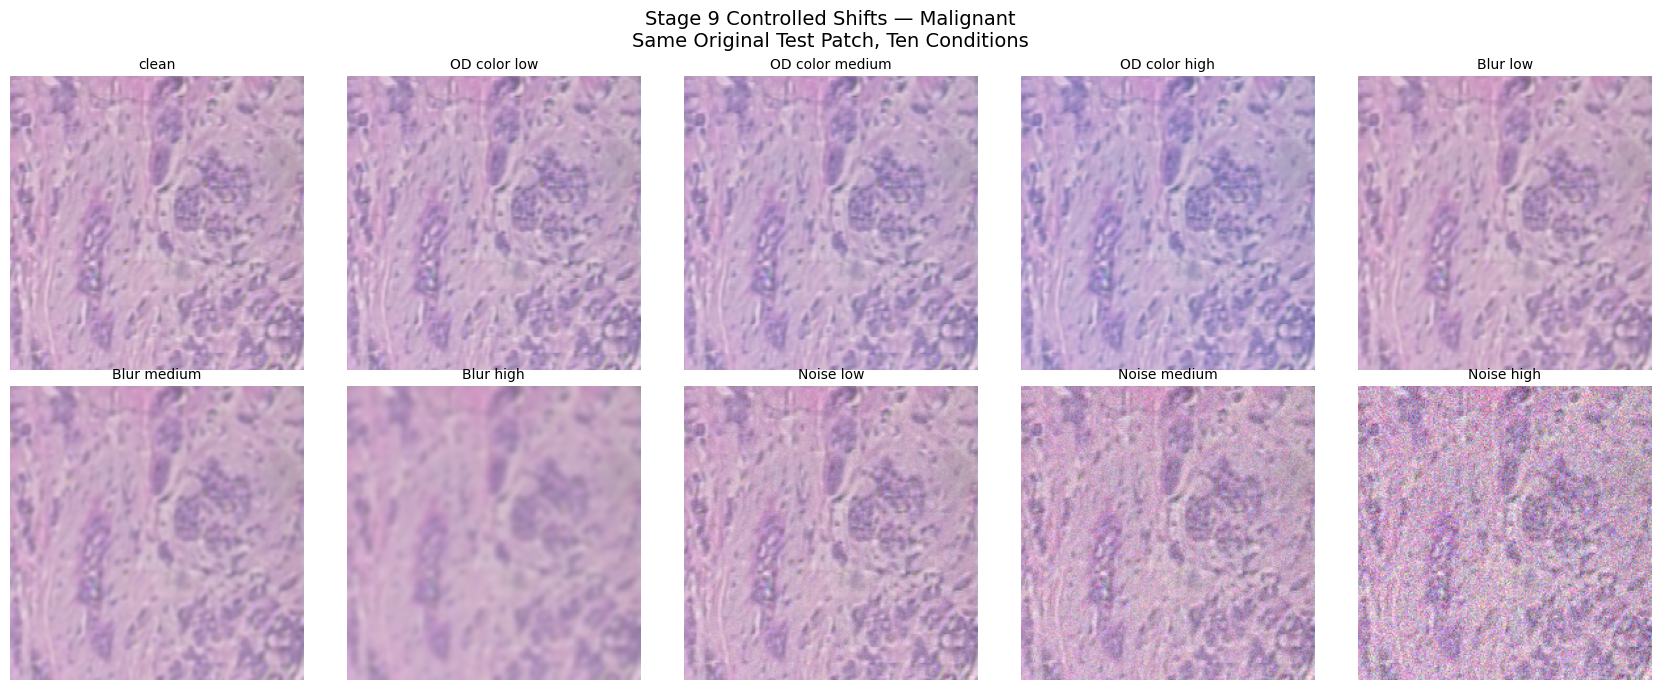

PASS: Malignant shift preview saved.

SHIFT IMPLEMENTATION VALIDATION


,diagnosis,condition,mean_absolute_rgb_change_0_to_255
0,Benign,clean,0.0000
1,Benign,stain_like_od_low,2.1227
2,Benign,stain_like_od_medium,4.2927
3,Benign,stain_like_od_high,8.6389
4,Benign,gaussian_blur_low,1.1074
5,Benign,gaussian_blur_medium,3.7678
6,Benign,gaussian_blur_high,8.2001
7,Benign,gaussian_noise_low,4.0495
8,Benign,gaussian_noise_medium,10.1277
9,Benign,gaussian_noise_high,20.1249



STAGE 9 — CELL 3 FINAL AUDIT
PASS: Original BreaKHis preprocessing recovered.
PASS: All 446 source images located.
PASS: Original patch coordinates preserved.
PASS: Benign patch reconstruction verified.
PASS: Malignant patch reconstruction verified.
PASS: Ten shift conditions implemented.
PASS: All transformations deterministic.
PASS: All shifted patches differ from clean.
PASS: Image dimensions preserved.
PASS: Benign and malignant previews saved.
PASS: Shift implementation audit saved.
PASS: Original Stage 9 protocol unchanged.
PASS: Calibration parameters unchanged.
PASS: No model inference or refitting performed.

Validation: /content/breast-histology-calibration/results/controlled_shifts/efficientnet_b0/stage9_shift_implementation_validation.csv
Audit: /content/breast-histology-calibration/results/controlled_shifts/efficientnet_b0/stage9_shift_implementation_audit.json
Benign preview: /content/breast-histology-calibration/results/controlled_shifts/efficientnet_b0/stage9_shift_pre

In [ ]:

# ============================================================
# Implement and Validate Controlled Image Shifts
# ============================================================

import ast
import kagglehub
import matplotlib.pyplot as plt

from PIL import Image
from scipy.ndimage import gaussian_filter
from matplotlib.colors import rgb_to_hsv

# ------------------------------------------------------------
# 1. Verify the locked Stage 9 protocol
# ------------------------------------------------------------

with open(
    STAGE9_PROTOCOL_PATH, encoding="utf-8"
) as f:
    locked_protocol = json.load(f)

assert locked_protocol["status"] == (
    "pre_inference_protocol_locked"
)

assert locked_protocol["test_images"] == 446
assert locked_protocol["patches_per_condition"] == 7087
assert locked_protocol["n_conditions"] == 10

assert locked_protocol[
    "clean_test_manifest_sha256"
] == sha256_file(TEST40_MANIFEST_PATH)

assert locked_protocol[
    "model_checkpoint_sha256"
] == EXPECTED_MODEL_SHA256

assert locked_protocol[
    "calibration_parameters_sha256"
] == sha256_file(PARAMETERS_PATH)

assert locked_protocol["conditions"][
    "stain_like_od"
] == STAIN_LIKE_OD_LEVELS

assert locked_protocol["conditions"][
    "gaussian_blur"
] == BLUR_SIGMA_LEVELS

assert locked_protocol["conditions"][
    "gaussian_noise"
] == NOISE_SIGMA_LEVELS

print("PASS: Stage 9 experimental protocol verified.")

# ------------------------------------------------------------
# 2. Restore the exact original patch preprocessing
# ------------------------------------------------------------

SOURCE_NOTEBOOK_PATH = (
    REPO_ROOT /
    "Notebooks/01_breakhis_data_audit_and_split.ipynb"
)

with open(SOURCE_NOTEBOOK_PATH, encoding="utf-8") as f:
    source_notebook = json.load(f)

original_constants = {
    "SOURCE_MPP_BREAKHIS": 0.49,
    "TARGET_MPP": 0.50,
    "PATCH_SIZE": 224,
    "GRID_SIZE": 4,
    "MAX_PATCHES": 16,
    "MIN_PATCH_TISSUE_FRACTION": 0.20,
    "OD_THRESHOLD": 0.08,
    "SATURATION_THRESHOLD": 0.05
}

required_functions = [
    "resample_to_target_mpp",
    "create_tissue_mask_hybrid",
    "generate_grid_coordinates",
    "extract_tissue_patches"
]

found_constants = {}
found_functions = {}

for cell in source_notebook["cells"]:

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:

        if isinstance(node, ast.Assign):

            for target in node.targets:

                if (
                    isinstance(target, ast.Name)
                    and target.id in original_constants
                ):
                    found_constants.setdefault(
                        target.id,
                        ast.literal_eval(node.value)
                    )

        if isinstance(node, ast.FunctionDef):

            if node.name in required_functions:
                found_functions.setdefault(
                    node.name,
                    ast.get_source_segment(source, node)
                )

assert set(found_constants) == set(original_constants)
assert set(found_functions) == set(required_functions)

for name, expected in original_constants.items():

    assert found_constants[name] == expected
    globals()[name] = expected

for name in required_functions:

    assert found_functions[name] is not None
    exec(found_functions[name], globals())

print("PASS: Original patch preprocessing restored.")
print("PASS: All eight preprocessing constants verified.")

# ------------------------------------------------------------
# 3. Locate BreaKHis source images
# ------------------------------------------------------------

DATASET_ROOT = Path(
    kagglehub.dataset_download("ambarish/breakhis")
)

assert DATASET_ROOT.is_dir()

missing_paths = [
    path
    for path in test40_manifest["relative_path"].unique()
    if not (DATASET_ROOT / path).is_file()
]

assert not missing_paths, (
    f"Missing source images: {missing_paths[:3]}"
)

print("Dataset root:", DATASET_ROOT)
print("PASS: All 446 original Test images located.")

# ------------------------------------------------------------
# 4. Define exactly ten experimental conditions
# ------------------------------------------------------------

STAGE9_CONDITIONS = {
    "clean": {
        "family": "clean",
        "severity": "none",
        "strength": 0.0
    }
}

for family, levels in [
    ("stain_like_od", STAIN_LIKE_OD_LEVELS),
    ("gaussian_blur", BLUR_SIGMA_LEVELS),
    ("gaussian_noise", NOISE_SIGMA_LEVELS)
]:

    for severity, strength in levels.items():

        condition_id = f"{family}_{severity}"

        STAGE9_CONDITIONS[condition_id] = {
            "family": family,
            "severity": severity,
            "strength": float(strength)
        }

assert len(STAGE9_CONDITIONS) == 10

assert list(STAGE9_CONDITIONS) == [
    "clean",
    "stain_like_od_low",
    "stain_like_od_medium",
    "stain_like_od_high",
    "gaussian_blur_low",
    "gaussian_blur_medium",
    "gaussian_blur_high",
    "gaussian_noise_low",
    "gaussian_noise_medium",
    "gaussian_noise_high"
]

print("PASS: Ten experimental conditions established.")

# ------------------------------------------------------------
# 5. Load a CLEAN patch using original saved coordinates
#
# No new tissue selection or patch selection.
# ------------------------------------------------------------

def load_stage9_clean_patch(manifest_row):

    source_path = (
        DATASET_ROOT / str(manifest_row["relative_path"])
    )

    with Image.open(source_path) as source_image:

        resized = resample_to_target_mpp(
            source_image.convert("RGB")
        )

    x = int(manifest_row["x"])
    y = int(manifest_row["y"])

    assert x >= 0 and y >= 0
    assert x + PATCH_SIZE <= resized.width
    assert y + PATCH_SIZE <= resized.height

    patch = resized.crop(
        (x, y, x + PATCH_SIZE, y + PATCH_SIZE)
    )

    assert patch.size == (224, 224)

    return patch


# ------------------------------------------------------------
# 6. Implement the three locked perturbation families
# ------------------------------------------------------------

def apply_stage9_shift(
    patch,
    condition_id,
    filename,
    patch_index
):

    assert condition_id in STAGE9_CONDITIONS

    condition = STAGE9_CONDITIONS[condition_id]

    family = condition["family"]
    strength = condition["strength"]

    clean = patch.convert("RGB")

    assert clean.size == (224, 224)

    if family == "clean":

        return clean.copy()

    rgb = (
        np.asarray(clean, dtype=np.float32)
        / 255.0
    )

    if family == "stain_like_od":

        # Fixed stain-like color perturbation:
        #
        # OD = -log(RGB)
        #
        # Change optical-density contributions
        # of red and blue channels in opposite
        # directions, leaving green unchanged.
        #
        # This is NOT validated H&E stain
        # separation or stain normalization.

        optical_density = -np.log(
            np.clip(rgb, 1e-6, 1.0)
        )

        channel_factors = np.array(
            [
                1.0 + strength,
                1.0,
                1.0 - strength
            ],
            dtype=np.float32
        )

        shifted_rgb = np.exp(
            -optical_density * channel_factors
        )

    elif family == "gaussian_blur":

        # Spatial Gaussian blur.
        # Strength is sigma in source-patch pixels.
        # Color channels are not blurred together.

        shifted_rgb = gaussian_filter(
            rgb,
            sigma=(strength, strength, 0.0),
            mode="reflect",
            truncate=4.0
        )

    elif family == "gaussian_noise":

        # Deterministic Gaussian noise:
        #
        # - Unique noise realization per patch
        # - Same standard-normal realization at
        #   all three severity levels
        # - Strength controls its amplitude
        # - No reliance on worker execution order

        seed_material = (
            f"{STAGE9_SEED}|"
            f"{filename}|"
            f"{int(patch_index)}|"
            "gaussian_noise"
        )

        digest = hashlib.sha256(
            seed_material.encode("utf-8")
        ).digest()

        patch_seed = int.from_bytes(
            digest[:8],
            byteorder="big"
        )

        rng = np.random.default_rng(patch_seed)

        standard_noise = rng.normal(
            loc=0.0,
            scale=1.0,
            size=rgb.shape
        )

        shifted_rgb = (
            rgb + strength * standard_noise
        )

    else:

        raise ValueError(
            f"Unexpected shift family: {family}"
        )

    shifted_rgb = np.clip(
        shifted_rgb,
        0.0,
        1.0
    )

    output = np.rint(
        shifted_rgb * 255.0
    ).astype(np.uint8)

    result = Image.fromarray(
        output,
        mode="RGB"
    )

    assert result.size == (224, 224)

    return result


print("PASS: Stain-like OD perturbation implemented.")
print("PASS: Gaussian blur implemented.")
print("PASS: Deterministic Gaussian noise implemented.")

# ------------------------------------------------------------
# 7. Verify original patch reconstruction
#
# Use one representative benign and malignant Test patch.
# ------------------------------------------------------------

example_rows = {}

for label, label_name in [
    (0, "Benign"),
    (1, "Malignant")
]:

    # Choose a high-tissue-content patch without
    # consulting model predictions.

    selected_row = (
        test40_manifest.loc[
            test40_manifest["label"].astype(int)
            == label
        ]
        .sort_values(
            ["tissue_fraction", "filename", "patch_index"],
            ascending=[False, True, True]
        )
        .iloc[0]
    )

    filename = str(selected_row["filename"])

    image_manifest = (
        test40_manifest.loc[
            test40_manifest["filename"] == filename
        ]
        .sort_values("patch_index")
    )

    with Image.open(
        DATASET_ROOT / selected_row["relative_path"]
    ) as source:

        extracted_patches, patch_info, used_fallback = (
            extract_tissue_patches(
                source.convert("RGB")
            )
        )

    assert len(extracted_patches) == len(image_manifest)

    expected_indices = (
        image_manifest["patch_index"]
        .astype(int)
        .tolist()
    )

    actual_indices = [
        int(info["patch_index"])
        for info in patch_info
    ]

    assert expected_indices == actual_indices

    for position, info in enumerate(patch_info):

        saved = image_manifest.iloc[position]

        assert int(info["x"]) == int(saved["x"])
        assert int(info["y"]) == int(saved["y"])

        np.testing.assert_allclose(
            float(info["tissue_fraction"]),
            float(saved["tissue_fraction"]),
            rtol=0,
            atol=1e-8
        )

    saved_fallback = (
        image_manifest["used_fallback"]
        .astype(str)
        .str.lower()
        .isin(["true", "1"])
        .all()
    )

    assert bool(used_fallback) == bool(saved_fallback)

    selected_patch_index = int(
        selected_row["patch_index"]
    )

    selected_position = actual_indices.index(
        selected_patch_index
    )

    reconstructed = load_stage9_clean_patch(
        selected_row
    )

    original_extracted = extracted_patches[
        selected_position
    ]

    assert np.array_equal(
        np.asarray(reconstructed),
        np.asarray(original_extracted)
    ), "Reconstructed patch differs from original."

    example_rows[label_name] = selected_row

    print(
        f"PASS: {label_name} patch reconstruction "
        "matches original extraction."
    )

# ------------------------------------------------------------
# 8. Test deterministic and nontrivial transformations
# ------------------------------------------------------------

validation_records = []

STAGE9_PREVIEW_PATHS = {}

for label_name, manifest_row in example_rows.items():

    clean_patch = load_stage9_clean_patch(
        manifest_row
    )

    clean_array = np.asarray(
        clean_patch, dtype=np.uint8
    )

    filename = str(manifest_row["filename"])
    patch_index = int(manifest_row["patch_index"])

    shifted_patches = []

    for condition_id in STAGE9_CONDITIONS:

        shifted = apply_stage9_shift(
            clean_patch,
            condition_id,
            filename,
            patch_index
        )

        repeated = apply_stage9_shift(
            clean_patch,
            condition_id,
            filename,
            patch_index
        )

        shifted_array = np.asarray(
            shifted, dtype=np.uint8
        )

        # The same patch and condition must
        # always yield the same pixels.

        assert np.array_equal(
            shifted_array,
            np.asarray(repeated)
        )

        assert shifted_array.shape == (
            224, 224, 3
        )

        assert shifted_array.dtype == np.uint8

        if condition_id == "clean":

            assert np.array_equal(
                shifted_array,
                clean_array
            )

        else:

            assert not np.array_equal(
                shifted_array,
                clean_array
            ), (
                f"No pixel change for {condition_id}"
            )

        mean_abs_change = float(
            np.mean(
                np.abs(
                    shifted_array.astype(np.float64)
                    -
                    clean_array.astype(np.float64)
                )
            )
        )

        validation_records.append({
            "diagnosis": label_name,
            "filename": filename,
            "patch_index": patch_index,
            "condition": condition_id,
            "mean_absolute_rgb_change_0_to_255":
                mean_abs_change,
            "patch_pixel_sha256":
                hashlib.sha256(
                    shifted_array.tobytes()
                ).hexdigest()
        })

        shifted_patches.append(
            (condition_id, shifted)
        )

    # --------------------------------------------------------
    # 9. Make a visual preview for this diagnosis
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        2, 5,
        figsize=(17, 7)
    )

    for ax, (condition_id, shifted) in zip(
        axes.flat,
        shifted_patches
    ):

        ax.imshow(shifted)

        display_name = (
            condition_id
            .replace("stain_like_od", "OD color")
            .replace("gaussian_blur", "Blur")
            .replace("gaussian_noise", "Noise")
            .replace("_", " ")
        )

        ax.set_title(
            display_name,
            fontsize=10
        )

        ax.axis("off")

    fig.suptitle(
        f"Stage 9 Controlled Shifts — {label_name}\n"
        f"Same Original Test Patch, Ten Conditions",
        fontsize=14
    )

    fig.tight_layout()

    preview_path = (
        STAGE9_RESULTS_DIR /
        f"stage9_shift_preview_{label_name.lower()}.png"
    )

    fig.savefig(
        preview_path,
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    assert preview_path.is_file()
    assert preview_path.stat().st_size > 10000

    STAGE9_PREVIEW_PATHS[
        label_name
    ] = preview_path

    print(
        f"PASS: {label_name} shift preview saved."
    )

# ------------------------------------------------------------
# 10. Save validation data and audit
# ------------------------------------------------------------

shift_validation = pd.DataFrame(
    validation_records
)

assert len(shift_validation) == 20

assert shift_validation[
    "patch_pixel_sha256"
].notna().all()

STAGE9_VALIDATION_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_shift_implementation_validation.csv"
)

shift_validation.to_csv(
    STAGE9_VALIDATION_PATH,
    index=False,
    float_format="%.17g"
)

STAGE9_IMPLEMENTATION_AUDIT_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_shift_implementation_audit.json"
)

implementation_audit = {
    "stage": 9,
    "status": "shift_implementation_validated",
    "protocol_sha256":
        sha256_file(STAGE9_PROTOCOL_PATH),
    "source_notebook_sha256":
        sha256_file(SOURCE_NOTEBOOK_PATH),
    "test_manifest_sha256":
        sha256_file(TEST40_MANIFEST_PATH),
    "conditions": STAGE9_CONDITIONS,
    "test_patch_size": [224, 224],
    "original_patch_coordinates_reused": True,
    "original_patch_selection_reused": True,
    "perturbation_before_normalization": True,
    "color_method":
        "RGB_optical_density_channel_scaling",
    "color_channel_multipliers":
        "[1+strength,1,1-strength]",
    "color_is_validated_he_stain_transform": False,
    "blur_method": "scipy_gaussian_filter",
    "blur_sigma_axes": [
        "sigma_pixels",
        "sigma_pixels",
        0.0
    ],
    "blur_boundary_mode": "reflect",
    "blur_truncate": 4.0,
    "noise_method": "additive_rgb_gaussian",
    "noise_sigma_in_rgb_unit_interval": True,
    "noise_seed": STAGE9_SEED,
    "noise_seed_components": [
        "seed",
        "filename",
        "patch_index",
        "gaussian_noise"
    ],
    "same_noise_realization_across_severities": True,
    "results_clipped_to_rgb_unit_interval": True,
    "outputs_quantized_to_uint8": True,
    "test_model_inference_performed": False,
    "calibrators_refitted": False,
    "validation_csv_sha256":
        sha256_file(STAGE9_VALIDATION_PATH),
    "preview_sha256": {
        label: sha256_file(path)
        for label, path in STAGE9_PREVIEW_PATHS.items()
    }
}

with open(
    STAGE9_IMPLEMENTATION_AUDIT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        implementation_audit,
        f,
        indent=2
    )

print("\n" + "=" * 70)
print("SHIFT IMPLEMENTATION VALIDATION")
print("=" * 70)

display(
    shift_validation[
        [
            "diagnosis",
            "condition",
            "mean_absolute_rgb_change_0_to_255"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 11. Final audit
# ------------------------------------------------------------

assert sha256_file(
    STAGE9_PROTOCOL_PATH
) == implementation_audit["protocol_sha256"]

assert sha256_file(
    STAGE9_VALIDATION_PATH
) == implementation_audit["validation_csv_sha256"]

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

print("\n" + "=" * 70)
print("STAGE 9 — CELL 3 FINAL AUDIT")
print("=" * 70)

print("PASS: Original BreaKHis preprocessing recovered.")
print("PASS: All 446 source images located.")
print("PASS: Original patch coordinates preserved.")
print("PASS: Benign patch reconstruction verified.")
print("PASS: Malignant patch reconstruction verified.")
print("PASS: Ten shift conditions implemented.")
print("PASS: All transformations deterministic.")
print("PASS: All shifted patches differ from clean.")
print("PASS: Image dimensions preserved.")
print("PASS: Benign and malignant previews saved.")
print("PASS: Shift implementation audit saved.")
print("PASS: Original Stage 9 protocol unchanged.")
print("PASS: Calibration parameters unchanged.")
print("PASS: No model inference or refitting performed.")

print("\nValidation:", STAGE9_VALIDATION_PATH)
print("Audit:", STAGE9_IMPLEMENTATION_AUDIT_PATH)

for label, path in STAGE9_PREVIEW_PATHS.items():
    print(f"{label} preview:", path)


In [ ]:

# ============================================================
# Restore Frozen EfficientNet-B0 and Prepare Shifted Data
# ============================================================

from torchvision.models import efficientnet_b0
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# 1. Verify locked Stage 9 inputs
# ------------------------------------------------------------

with open(STAGE9_PROTOCOL_PATH, encoding="utf-8") as f:
    stage9_protocol = json.load(f)

with open(
    STAGE9_IMPLEMENTATION_AUDIT_PATH,
    encoding="utf-8"
) as f:
    implementation_audit = json.load(f)

assert stage9_protocol["status"] == (
    "pre_inference_protocol_locked"
)

assert implementation_audit["status"] == (
    "shift_implementation_validated"
)

assert implementation_audit[
    "protocol_sha256"
] == sha256_file(STAGE9_PROTOCOL_PATH)

assert implementation_audit[
    "conditions"
] == STAGE9_CONDITIONS

assert stage9_protocol["test_images"] == 446
assert stage9_protocol["patches_per_condition"] == 7087

assert len(STAGE9_CONDITIONS) == 10

assert sha256_file(
    TEST40_MANIFEST_PATH
) == stage9_protocol[
    "clean_test_manifest_sha256"
]

assert sha256_file(
    TEST40_PREDICTIONS_PATH
) == stage9_protocol[
    "clean_test_predictions_sha256"
]

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

assert len(test40_manifest) == 7087

print("=" * 70)
print("STAGE 9 — FROZEN INFERENCE PREPARATION")
print("=" * 70)

print("PASS: Stage 9 protocol integrity verified.")
print("PASS: Shift implementation audit verified.")
print("PASS: Original Test patch manifest verified.")
print("PASS: Original clean predictions verified.")
print("PASS: Locked calibration parameters verified.")

# ------------------------------------------------------------
# 2. Locate or restore the final Epoch 5 checkpoint
# ------------------------------------------------------------

STAGE9_CHECKPOINT_PATH = Path(
    "/content/CIS631_model_checkpoints/"
    "efficientnet_b0/final_development/"
    "efficientnet_b0_final_epoch5.pt"
)

STAGE9_CHECKPOINT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

if STAGE9_CHECKPOINT_PATH.is_file():

    print("\nExisting final model checkpoint located.")

else:

    print("\nUpload your final Stage 6 backup ZIP:")
    print("CIS631_EfficientNetB0_Final_Stage6_Backup.zip")

    uploaded = files.upload()

    assert len(uploaded) == 1, (
        "Upload exactly one checkpoint backup ZIP."
    )

    uploaded_name, uploaded_bytes = next(
        iter(uploaded.items())
    )

    assert uploaded_name == (
        "CIS631_EfficientNetB0_Final_Stage6_Backup.zip"
    )

    with zipfile.ZipFile(
        io.BytesIO(uploaded_bytes)
    ) as archive:

        assert archive.testzip() is None

        checkpoint_members = [
            name for name in archive.namelist()
            if name.endswith(
                "efficientnet_b0_final_epoch5.pt"
            )
            and not name.endswith("/")
        ]

        assert len(checkpoint_members) == 1

        temporary_path = (
            STAGE9_CHECKPOINT_PATH.with_suffix(".pt.tmp")
        )

        with archive.open(
            checkpoint_members[0]
        ) as source, open(
            temporary_path, "wb"
        ) as destination:

            for chunk in iter(
                lambda: source.read(1024 * 1024),
                b""
            ):
                destination.write(chunk)

        assert sha256_file(
            temporary_path
        ) == EXPECTED_MODEL_SHA256, (
            "Incorrect final model checkpoint."
        )

        temporary_path.replace(
            STAGE9_CHECKPOINT_PATH
        )

assert sha256_file(
    STAGE9_CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

print("PASS: Final Epoch 5 checkpoint SHA-256 verified.")

# ------------------------------------------------------------
# 3. Restore the original EfficientNet-B0 architecture
# ------------------------------------------------------------

stage9_checkpoint = torch.load(
    STAGE9_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

assert stage9_checkpoint["epoch_completed"] == 5

stage9_model = efficientnet_b0(
    weights=None
)

# Preserve original Sequential classifier.
# Replace only the final classification layer.

stage9_model.classifier[1] = torch.nn.Linear(
    1280, 1
)

stage9_model.load_state_dict(
    stage9_checkpoint["model_state_dict"],
    strict=True
)

stage9_model = stage9_model.to(DEVICE)
stage9_model.eval()

for parameter in stage9_model.parameters():
    parameter.requires_grad_(False)

assert not stage9_model.training

assert all(
    not parameter.requires_grad
    for parameter in stage9_model.parameters()
)

# Synthetic inference verifies the architecture only.
# No Test images are passed through the model here.

with torch.inference_mode():

    dummy_output = stage9_model(
        torch.zeros(
            (1, 3, 224, 224),
            device=DEVICE
        )
    )

assert dummy_output.shape == (1, 1)
assert torch.isfinite(dummy_output).all()

del stage9_checkpoint

print("PASS: Final EfficientNet-B0 model restored.")
print("PASS: Original classifier architecture preserved.")
print("PASS: Model weights loaded strictly.")
print("PASS: All CNN parameters frozen.")
print("PASS: Synthetic inference verified.")

# ------------------------------------------------------------
# 4. Restore original Stage 8 Dataset implementation
#
# This allows direct input-level comparison between
# the established clean loader and our new shift loader.
# ------------------------------------------------------------

DEVELOPMENT_NOTEBOOK_PATH = (
    REPO_ROOT /
    "Notebooks/03_breakhis_formal_development.ipynb"
)

with open(
    DEVELOPMENT_NOTEBOOK_PATH,
    encoding="utf-8"
) as f:
    development_notebook = json.load(f)

dataset_sources = []

for cell in development_notebook["cells"]:

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:

        if (
            isinstance(node, ast.ClassDef)
            and node.name == "BreakHisPatchDataset"
        ):

            dataset_sources.append(
                ast.get_source_segment(source, node)
            )

assert dataset_sources
assert dataset_sources[-1] is not None

exec(dataset_sources[-1], globals())

print("PASS: Original Development Dataset class restored.")

# ------------------------------------------------------------
# 5. Restore the exact Stage 8 inference normalization
# ------------------------------------------------------------

stage9_inference_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

STAGE9_BATCH_SIZE = 32
STAGE9_NUM_WORKERS = 2

# Original loader used during clean Test inference.

original_clean_dataset = BreakHisPatchDataset(
    manifest=test40_manifest,
    dataset_root=DATASET_ROOT,
    transform=stage9_inference_transform
)

assert len(original_clean_dataset) == 7087

print("PASS: Original Stage 8 normalization restored.")
print("PASS: Original clean Dataset initialized.")

# ------------------------------------------------------------
# 6. Define deterministic shifted-patch Dataset
#
# Reuse exactly the original patch coordinates.
# Shift before normalization.
# Preserve all identifying metadata.
# ------------------------------------------------------------

class Stage9ShiftDataset(Dataset):

    def __init__(
        self,
        manifest,
        condition_id,
        transform
    ):

        assert condition_id in STAGE9_CONDITIONS

        self.manifest = (
            manifest.copy()
            .reset_index(drop=True)
        )

        self.condition_id = condition_id
        self.transform = transform

        assert len(self.manifest) == 7087

        assert not self.manifest.duplicated(
            ["filename", "patch_index"]
        ).any()

    def __len__(self):

        return len(self.manifest)

    def __getitem__(self, index):

        row = self.manifest.iloc[index]

        filename = str(row["filename"])
        patient_id = str(row["patient_id"])
        patch_index = int(row["patch_index"])
        label = int(row["label"])

        assert label in (0, 1)

        # Reconstruct the original clean tissue patch
        # using its saved Stage 8 coordinates.

        clean_patch = load_stage9_clean_patch(
            row
        )

        # Apply the selected shift.
        # The clean condition returns an unchanged copy.

        shifted_patch = apply_stage9_shift(
            patch=clean_patch,
            condition_id=self.condition_id,
            filename=filename,
            patch_index=patch_index
        )

        # ImageNet normalization is performed AFTER
        # the perturbation.

        image_tensor = self.transform(
            shifted_patch
        )

        assert image_tensor.shape == (
            3, 224, 224
        )

        return {
            "image": image_tensor,
            "label": torch.tensor(
                label,
                dtype=torch.long
            ),
            "filename": filename,
            "patient_id": patient_id,
            "patch_index": patch_index
        }


# ------------------------------------------------------------
# 7. Prepare Dataset for each experimental condition
# ------------------------------------------------------------

stage9_datasets = {}

for condition_id in STAGE9_CONDITIONS:

    dataset = Stage9ShiftDataset(
        manifest=test40_manifest,
        condition_id=condition_id,
        transform=stage9_inference_transform
    )

    assert len(dataset) == 7087

    stage9_datasets[condition_id] = dataset

assert len(stage9_datasets) == 10

# Create DataLoaders on demand.
# This avoids keeping multiple multiprocessing
# iterators open simultaneously.

def make_stage9_loader(condition_id):

    assert condition_id in stage9_datasets

    return DataLoader(
        stage9_datasets[condition_id],
        batch_size=STAGE9_BATCH_SIZE,
        shuffle=False,
        num_workers=STAGE9_NUM_WORKERS,
        pin_memory=True,
        drop_last=False,
        persistent_workers=False
    )


print("PASS: All ten condition Datasets initialized.")

# ------------------------------------------------------------
# 8. Verify exact CLEAN input equivalence with Stage 8
#
# This protects against a hidden preprocessing mismatch.
# No model predictions are generated here.
# ------------------------------------------------------------

clean_shift_dataset = stage9_datasets["clean"]

sample_indices = [
    0,
    1,
    15,
    100,
    1000,
    3500,
    6000,
    7086
]

for index in sample_indices:

    original_sample = original_clean_dataset[
        index
    ]

    new_sample = clean_shift_dataset[
        index
    ]

    assert torch.equal(
        original_sample["image"],
        new_sample["image"]
    ), (
        f"Clean preprocessing mismatch at index {index}"
    )

    assert int(original_sample["label"]) == int(
        new_sample["label"]
    )

    assert str(original_sample["filename"]) == (
        new_sample["filename"]
    )

    assert str(original_sample["patient_id"]) == (
        new_sample["patient_id"]
    )

    assert int(original_sample["patch_index"]) == (
        new_sample["patch_index"]
    )

print(
    "PASS: Eight clean Test patches match "
    "the original Stage 8 Dataset exactly."
)

# ------------------------------------------------------------
# 9. Verify shifted Dataset outputs
# ------------------------------------------------------------

for condition_id in STAGE9_CONDITIONS:

    dataset = stage9_datasets[condition_id]

    first_sample = dataset[0]
    repeated_sample = dataset[0]

    assert torch.equal(
        first_sample["image"],
        repeated_sample["image"]
    ), (
        f"Nondeterministic output: {condition_id}"
    )

    assert first_sample["image"].shape == (
        3, 224, 224
    )

    assert torch.isfinite(
        first_sample["image"]
    ).all()

    assert first_sample["filename"] == (
        str(test40_manifest.iloc[0]["filename"])
    )

    assert first_sample["patient_id"] == (
        str(test40_manifest.iloc[0]["patient_id"])
    )

    assert first_sample["patch_index"] == (
        int(test40_manifest.iloc[0]["patch_index"])
    )

    assert int(first_sample["label"]) == (
        int(test40_manifest.iloc[0]["label"])
    )

    if condition_id != "clean":

        assert not torch.equal(
            first_sample["image"],
            clean_shift_dataset[0]["image"]
        )

    assert len(
        make_stage9_loader(condition_id)
    ) == 222

    print(
        f"PASS: {condition_id} "
        "— deterministic input verified."
    )

# ------------------------------------------------------------
# 10. Check preserved Test image and patient coverage
# ------------------------------------------------------------

expected_filenames = set(
    test40_predictions["filename"]
)

expected_patients = set(
    test40_predictions["patient_id"]
)

for condition_id, dataset in stage9_datasets.items():

    assert set(
        dataset.manifest["filename"]
    ) == expected_filenames

    assert set(
        dataset.manifest["patient_id"]
    ) == expected_patients

    assert dataset.manifest[
        "filename"
    ].nunique() == 446

    assert dataset.manifest[
        "patient_id"
    ].nunique() == 16

    assert len(dataset) == 7087

print("PASS: Identical Test images across conditions.")
print("PASS: Identical 16 Test patients across conditions.")
print("PASS: Original patch count preserved.")

# ------------------------------------------------------------
# 11. Verify all locked parameters again
# ------------------------------------------------------------

assert np.isclose(
    LOCKED_TEMPERATURE,
    4.069193139210192,
    rtol=0,
    atol=1e-12
)

assert np.isclose(
    LOCKED_PLATT_SLOPE,
    0.29141657172422586,
    rtol=0,
    atol=1e-12
)

assert np.isclose(
    LOCKED_PLATT_INTERCEPT,
    -0.7096590060187311,
    rtol=0,
    atol=1e-12
)

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

assert sha256_file(
    STAGE9_CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

# ------------------------------------------------------------
# 12. Save inference readiness audit
# ------------------------------------------------------------

STAGE9_INFERENCE_SETUP_AUDIT_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_inference_setup_audit.json"
)

stage9_setup_audit = {
    "stage": 9,
    "status": "shifted_inference_ready",
    "protocol_sha256":
        sha256_file(STAGE9_PROTOCOL_PATH),
    "implementation_audit_sha256":
        sha256_file(STAGE9_IMPLEMENTATION_AUDIT_PATH),
    "checkpoint_sha256":
        EXPECTED_MODEL_SHA256,
    "calibration_parameters_sha256":
        sha256_file(PARAMETERS_PATH),
    "original_test_manifest_sha256":
        sha256_file(TEST40_MANIFEST_PATH),
    "original_clean_predictions_sha256":
        sha256_file(TEST40_PREDICTIONS_PATH),
    "architecture": "efficientnet_b0",
    "final_checkpoint_epoch": 5,
    "model_in_eval_mode": True,
    "all_model_parameters_frozen": True,
    "patches_per_condition": 7087,
    "images_per_condition": 446,
    "patients_per_condition": 16,
    "total_conditions": 10,
    "shifted_conditions": 9,
    "batch_size": STAGE9_BATCH_SIZE,
    "num_workers": STAGE9_NUM_WORKERS,
    "shuffle": False,
    "drop_last": False,
    "clean_tensor_equivalence_samples": 8,
    "clean_tensor_equivalence_passed": True,
    "normalization": "ImageNet_mean_and_std",
    "shift_applied_before_normalization": True,
    "original_patch_coordinates_preserved": True,
    "original_patch_selection_preserved": True,
    "model_predictions_generated": False,
    "cnn_retrained": False,
    "calibrators_refitted": False,
    "test_based_tuning": False
}

if STAGE9_INFERENCE_SETUP_AUDIT_PATH.is_file():

    with open(
        STAGE9_INFERENCE_SETUP_AUDIT_PATH,
        encoding="utf-8"
    ) as f:
        existing_setup_audit = json.load(f)

    assert existing_setup_audit == stage9_setup_audit

else:

    with open(
        STAGE9_INFERENCE_SETUP_AUDIT_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            stage9_setup_audit,
            f,
            indent=2
        )

print("PASS: Stage 9 inference setup audit saved.")

# ------------------------------------------------------------
# 13. Final readiness summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STAGE 9 — SHIFTED INFERENCE READINESS")
print("=" * 70)

print("Model: EfficientNet-B0")
print("Checkpoint: Final Epoch 5")
print("Device:", DEVICE)

print("\nClean baseline:")
print("Images:", 446)
print("Patches:", 7087)
print("Source: Verified Stage 8 predictions")

print("\nShifted conditions:", 9)
print("Patches per shifted condition:", 7087)

print(
    "Total shifted patch evaluations:",
    9 * 7087
)

print(
    "Total shifted inference batches:",
    9 * 222
)

print("\n" + "=" * 70)
print("STAGE 9 — CELL 4 FINAL AUDIT")
print("=" * 70)

print("PASS: Final Epoch 5 model checkpoint restored.")
print("PASS: Model checkpoint SHA-256 verified.")
print("PASS: Original classifier structure preserved.")
print("PASS: Model parameters frozen.")
print("PASS: Original clean Dataset restored.")
print("PASS: Exact Stage 8 input normalization reused.")
print("PASS: Stage 9 shifted Dataset implemented.")
print("PASS: Ten condition Datasets initialized.")
print("PASS: Clean input equivalence verified.")
print("PASS: All shifted inputs deterministic.")
print("PASS: Original patch coordinates preserved.")
print("PASS: Original Test image identities preserved.")
print("PASS: All nine shifted conditions ready.")
print("PASS: Both calibration methods remain locked.")
print("PASS: Stage 9 inference readiness audit saved.")
print("PASS: No Test performance metrics calculated.")
print("PASS: No CNN retraining or recalibration.")

print(
    "\nSetup audit:",
    STAGE9_INFERENCE_SETUP_AUDIT_PATH
)


STAGE 9 — FROZEN INFERENCE PREPARATION
PASS: Stage 9 protocol integrity verified.
PASS: Shift implementation audit verified.
PASS: Original Test patch manifest verified.
PASS: Original clean predictions verified.
PASS: Locked calibration parameters verified.

Upload your final Stage 6 backup ZIP:
CIS631_EfficientNetB0_Final_Stage6_Backup.zip


Saving CIS631_EfficientNetB0_Final_Stage6_Backup.zip to CIS631_EfficientNetB0_Final_Stage6_Backup.zip
PASS: Final Epoch 5 checkpoint SHA-256 verified.
PASS: Final EfficientNet-B0 model restored.
PASS: Original classifier architecture preserved.
PASS: Model weights loaded strictly.
PASS: All CNN parameters frozen.
PASS: Synthetic inference verified.
PASS: Original Development Dataset class restored.
PASS: Original Stage 8 normalization restored.
PASS: Original clean Dataset initialized.
PASS: All ten condition Datasets initialized.
PASS: Eight clean Test patches match the original Stage 8 Dataset exactly.
PASS: clean — deterministic input verified.
PASS: stain_like_od_low — deterministic input verified.
PASS: stain_like_od_medium — deterministic input verified.


/tmp/ipykernel_578/3252629307.py:370: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  result = Image.fromarray(


PASS: stain_like_od_high — deterministic input verified.
PASS: gaussian_blur_low — deterministic input verified.
PASS: gaussian_blur_medium — deterministic input verified.
PASS: gaussian_blur_high — deterministic input verified.
PASS: gaussian_noise_low — deterministic input verified.
PASS: gaussian_noise_medium — deterministic input verified.
PASS: gaussian_noise_high — deterministic input verified.
PASS: Identical Test images across conditions.
PASS: Identical 16 Test patients across conditions.
PASS: Original patch count preserved.
PASS: Stage 9 inference setup audit saved.

STAGE 9 — SHIFTED INFERENCE READINESS
Model: EfficientNet-B0
Checkpoint: Final Epoch 5
Device: cuda

Clean baseline:
Images: 446
Patches: 7087
Source: Verified Stage 8 predictions

Shifted conditions: 9
Patches per shifted condition: 7087
Total shifted patch evaluations: 63783
Total shifted inference batches: 1998

STAGE 9 — CELL 4 FINAL AUDIT
PASS: Final Epoch 5 model checkpoint restored.
PASS: Model checkpoint

In [ ]:

# ============================================================
# Frozen Inference on All Nine Controlled Shift Conditions
# ============================================================

from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Verify frozen model and experiment provenance
# ------------------------------------------------------------

with open(STAGE9_PROTOCOL_PATH, encoding="utf-8") as f:
    stage9_protocol = json.load(f)

with open(
    STAGE9_INFERENCE_SETUP_AUDIT_PATH,
    encoding="utf-8"
) as f:
    setup_audit = json.load(f)

assert stage9_protocol["status"] == (
    "pre_inference_protocol_locked"
)

assert setup_audit["status"] == "shifted_inference_ready"

assert setup_audit["protocol_sha256"] == (
    sha256_file(STAGE9_PROTOCOL_PATH)
)

assert sha256_file(
    STAGE9_CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

assert sha256_file(
    TEST40_MANIFEST_PATH
) == stage9_protocol[
    "clean_test_manifest_sha256"
]

assert sha256_file(
    TEST40_PREDICTIONS_PATH
) == stage9_protocol[
    "clean_test_predictions_sha256"
]

assert not stage9_model.training

assert all(
    not p.requires_grad
    for p in stage9_model.parameters()
)

assert len(test40_manifest) == 7087

# Freeze a copy of model parameters and buffers
# for verification after all inference conditions.

stage9_model_state_before = {
    name: tensor.detach().cpu().clone()
    for name, tensor in stage9_model.state_dict().items()
}

print("=" * 70)
print("STAGE 9 — CONTROLLED SHIFT INFERENCE")
print("=" * 70)

print("PASS: Final CNN checkpoint verified.")
print("PASS: Calibration parameters verified.")
print("PASS: Stage 9 protocol verified.")
print("PASS: Model remains frozen.")
print("PASS: Original 40x Test reference verified.")

# ------------------------------------------------------------
# 2. Set up conditions and prediction functions
# ------------------------------------------------------------

shift_conditions = [
    condition
    for condition in STAGE9_CONDITIONS
    if condition != "clean"
]

assert len(shift_conditions) == 9

assert len(stage9_datasets) == 10

def stage9_sigmoid(values):

    array = np.asarray(
        values,
        dtype=np.float64
    )

    return torch.sigmoid(
        torch.from_numpy(array)
    ).numpy()


clean_reference = (
    test40_predictions
    .set_index("filename")
)

assert clean_reference.index.is_unique
assert len(clean_reference) == 446

condition_image_parts = []
condition_file_paths = {}
condition_audit_paths = {}

# ------------------------------------------------------------
# 3. Define independent output validation
#
# This is used for both newly generated and
# previously saved predictions.
# ------------------------------------------------------------

def verify_stage9_condition(
    condition_id,
    patch_predictions,
    image_predictions
):

    assert len(patch_predictions) == 7087
    assert len(image_predictions) == 446

    assert image_predictions["filename"].is_unique

    assert not patch_predictions.duplicated(
        ["filename", "patch_index"]
    ).any()

    assert patch_predictions["condition"].eq(
        condition_id
    ).all()

    assert image_predictions["condition"].eq(
        condition_id
    ).all()

    # The original patch order and identities
    # must remain unchanged.

    for column in [
        "filename",
        "patient_id",
        "patch_index",
        "label"
    ]:

        assert (
            patch_predictions[column]
            .astype(str)
            .tolist()
            ==
            test40_manifest[column]
            .astype(str)
            .tolist()
        )

    assert np.isfinite(
        patch_predictions["patch_logit"]
        .to_numpy(dtype=np.float64)
    ).all()

    assert np.isfinite(
        image_predictions["image_logit"]
        .to_numpy(dtype=np.float64)
    ).all()

    assert set(
        image_predictions["filename"]
    ) == set(clean_reference.index)

    assert image_predictions[
        "patient_id"
    ].nunique() == 16

    assert image_predictions[
        "n_patches"
    ].sum() == 7087

    # Verify the image aggregation using
    # independent group-by calculations.

    calculated_image_logits = (
        patch_predictions
        .groupby("filename")["patch_logit"]
        .mean()
    )

    calculated_patch_counts = (
        patch_predictions
        .groupby("filename")
        .size()
    )

    filenames = image_predictions[
        "filename"
    ].tolist()

    np.testing.assert_allclose(
        image_predictions[
            "image_logit"
        ].to_numpy(dtype=np.float64),
        calculated_image_logits.loc[
            filenames
        ].to_numpy(dtype=np.float64),
        rtol=0,
        atol=1e-12
    )

    np.testing.assert_array_equal(
        image_predictions[
            "n_patches"
        ].to_numpy(dtype=int),
        calculated_patch_counts.loc[
            filenames
        ].to_numpy(dtype=int)
    )

    # Check labels and patient identities against
    # the original clean Test predictions.

    aligned_clean = clean_reference.loc[
        filenames
    ]

    np.testing.assert_array_equal(
        image_predictions["label"]
        .to_numpy(dtype=int),
        aligned_clean["label"]
        .to_numpy(dtype=int)
    )

    assert (
        image_predictions["patient_id"]
        .astype(str)
        .tolist()
        ==
        aligned_clean["patient_id"]
        .astype(str)
        .tolist()
    )

    np.testing.assert_array_equal(
        image_predictions["n_patches"]
        .to_numpy(dtype=int),
        aligned_clean["n_patches"]
        .to_numpy(dtype=int)
    )

    # Verify locked calibration formulas.

    z = image_predictions[
        "image_logit"
    ].to_numpy(dtype=np.float64)

    expected_probabilities = {
        "probability":
            stage9_sigmoid(z),

        "temperature_probability":
            stage9_sigmoid(
                z / LOCKED_TEMPERATURE
            ),

        "platt_probability":
            stage9_sigmoid(
                LOCKED_PLATT_SLOPE * z
                + LOCKED_PLATT_INTERCEPT
            )
    }

    for column, expected in (
        expected_probabilities.items()
    ):

        actual = image_predictions[
            column
        ].to_numpy(dtype=np.float64)

        assert np.isfinite(actual).all()

        assert (
            (actual >= 0)
            &
            (actual <= 1)
        ).all()

        np.testing.assert_allclose(
            actual,
            expected,
            rtol=0,
            atol=1e-12
        )

    # Verify classification decisions.
    # Temperature scaling preserves the
    # original 0.5 decision boundary.

    for probability_column, prediction_column in [
        ("probability", "prediction"),
        (
            "temperature_probability",
            "temperature_prediction"
        ),
        (
            "platt_probability",
            "platt_prediction"
        )
    ]:

        expected_class = (
            image_predictions[probability_column]
            .to_numpy(dtype=np.float64) >= 0.5
        ).astype(int)

        np.testing.assert_array_equal(
            image_predictions[prediction_column]
            .to_numpy(dtype=int),
            expected_class
        )

    np.testing.assert_array_equal(
        image_predictions["prediction"]
        .to_numpy(dtype=int),
        image_predictions[
            "temperature_prediction"
        ].to_numpy(dtype=int)
    )

    assert sha256_file(
        STAGE9_CHECKPOINT_PATH
    ) == EXPECTED_MODEL_SHA256

    return True


# ------------------------------------------------------------
# 4. Run all nine shifted conditions separately
# ------------------------------------------------------------

for condition_id in shift_conditions:

    condition_info = STAGE9_CONDITIONS[
        condition_id
    ]

    print("\n" + "=" * 70)
    print("CONDITION:", condition_id)
    print("=" * 70)

    print("Family:", condition_info["family"])
    print("Severity:", condition_info["severity"])
    print("Strength:", condition_info["strength"])

    patch_output_path = (
        STAGE9_RESULTS_DIR /
        f"stage9_{condition_id}_patch_predictions.csv"
    )

    image_output_path = (
        STAGE9_RESULTS_DIR /
        f"stage9_{condition_id}_image_predictions.csv"
    )

    condition_audit_path = (
        STAGE9_RESULTS_DIR /
        f"stage9_{condition_id}_inference_audit.json"
    )

    condition_paths = [
        patch_output_path,
        image_output_path,
        condition_audit_path
    ]

    already_complete = all(
        path.is_file()
        for path in condition_paths
    )

    # --------------------------------------------------------
    # 4A. Resume previously completed condition
    # --------------------------------------------------------

    if already_complete:

        with open(
            condition_audit_path,
            encoding="utf-8"
        ) as f:
            condition_audit = json.load(f)

        assert condition_audit["status"] == (
            "condition_inference_completed"
        )

        assert condition_audit[
            "condition"
        ] == condition_id

        assert condition_audit[
            "checkpoint_sha256"
        ] == EXPECTED_MODEL_SHA256

        assert condition_audit[
            "protocol_sha256"
        ] == sha256_file(STAGE9_PROTOCOL_PATH)

        assert condition_audit[
            "implementation_audit_sha256"
        ] == sha256_file(
            STAGE9_IMPLEMENTATION_AUDIT_PATH
        )

        assert condition_audit[
            "clean_manifest_sha256"
        ] == sha256_file(TEST40_MANIFEST_PATH)

        assert condition_audit[
            "clean_predictions_sha256"
        ] == sha256_file(TEST40_PREDICTIONS_PATH)

        assert condition_audit[
            "calibration_parameters_sha256"
        ] == sha256_file(PARAMETERS_PATH)

        assert condition_audit[
            "patch_predictions_sha256"
        ] == sha256_file(patch_output_path)

        assert condition_audit[
            "image_predictions_sha256"
        ] == sha256_file(image_output_path)

        patch_predictions = pd.read_csv(
            patch_output_path,
            dtype={
                "filename": str,
                "patient_id": str
            }
        )

        image_predictions = pd.read_csv(
            image_output_path,
            dtype={
                "filename": str,
                "patient_id": str
            }
        )

        print(
            "Previously completed condition verified."
        )
        print(
            "Reusing saved predictions."
        )

    else:

        if any(
            path.is_file()
            for path in condition_paths
        ):

            print(
                "Incomplete condition files detected."
            )
            print(
                "Recomputing this condition safely."
            )

        # ----------------------------------------------------
        # 4B. Frozen CNN inference
        # ----------------------------------------------------

        loader = make_stage9_loader(
            condition_id
        )

        assert len(loader) == 222

        collected_logits = []
        collected_filenames = []
        collected_patients = []
        collected_patch_indices = []
        collected_labels = []

        stage9_model.eval()

        with torch.inference_mode():

            for batch in tqdm(
                loader,
                desc=condition_id
            ):

                images = batch[
                    "image"
                ].to(
                    DEVICE,
                    non_blocking=True
                )

                logits = stage9_model(
                    images
                ).reshape(-1)

                assert torch.isfinite(
                    logits
                ).all()

                collected_logits.extend(
                    logits.float()
                    .cpu()
                    .numpy()
                    .astype(np.float64)
                    .tolist()
                )

                collected_filenames.extend(
                    list(batch["filename"])
                )

                collected_patients.extend(
                    list(batch["patient_id"])
                )

                collected_patch_indices.extend(
                    batch["patch_index"]
                    .cpu()
                    .tolist()
                )

                collected_labels.extend(
                    batch["label"]
                    .cpu()
                    .tolist()
                )

        assert len(collected_logits) == 7087

        # ----------------------------------------------------
        # 4C. Verify alignment before saving
        # ----------------------------------------------------

        assert collected_filenames == (
            test40_manifest["filename"]
            .astype(str)
            .tolist()
        )

        assert collected_patients == (
            test40_manifest["patient_id"]
            .astype(str)
            .tolist()
        )

        assert collected_patch_indices == (
            test40_manifest["patch_index"]
            .astype(int)
            .tolist()
        )

        np.testing.assert_array_equal(
            np.asarray(
                collected_labels,
                dtype=int
            ),
            test40_manifest["label"]
            .to_numpy(dtype=int)
        )

        print("PASS: All 7,087 patch predictions aligned.")

        # ----------------------------------------------------
        # 4D. Build patch-level predictions
        # ----------------------------------------------------

        patch_predictions = (
            test40_manifest
            .copy()
            .reset_index(drop=True)
        )

        patch_predictions["condition"] = (
            condition_id
        )

        patch_predictions["patch_logit"] = (
            np.asarray(
                collected_logits,
                dtype=np.float64
            )
        )

        patch_predictions[
            "patch_probability"
        ] = stage9_sigmoid(
            patch_predictions["patch_logit"]
            .to_numpy(dtype=np.float64)
        )

        # ----------------------------------------------------
        # 4E. Aggregate to image-level logits
        # ----------------------------------------------------

        for column in [
            "patient_id",
            "diagnosis",
            "label"
        ]:

            assert (
                patch_predictions
                .groupby("filename")[column]
                .nunique()
                .max()
            ) == 1

        image_predictions = (
            patch_predictions
            .groupby(
                "filename",
                as_index=False,
                sort=False
            )
            .agg(
                patient_id=("patient_id", "first"),
                diagnosis=("diagnosis", "first"),
                label=("label", "first"),
                n_patches=("patch_index", "size"),
                image_logit=("patch_logit", "mean"),
                mean_patch_probability=(
                    "patch_probability", "mean"
                )
            )
        )

        image_predictions["magnification"] = 40

        image_predictions["condition"] = condition_id

        image_predictions["shift_family"] = (
            condition_info["family"]
        )

        image_predictions["shift_severity"] = (
            condition_info["severity"]
        )

        image_predictions["shift_strength"] = (
            condition_info["strength"]
        )

        # ----------------------------------------------------
        # 4F. Apply LOCKED calibration methods
        # ----------------------------------------------------

        image_logits = (
            image_predictions["image_logit"]
            .to_numpy(dtype=np.float64)
        )

        image_predictions["probability"] = (
            stage9_sigmoid(image_logits)
        )

        image_predictions[
            "temperature_probability"
        ] = stage9_sigmoid(
            image_logits / LOCKED_TEMPERATURE
        )

        image_predictions[
            "platt_probability"
        ] = stage9_sigmoid(
            LOCKED_PLATT_SLOPE * image_logits
            + LOCKED_PLATT_INTERCEPT
        )

        for probability_column, prediction_column in [
            ("probability", "prediction"),
            (
                "temperature_probability",
                "temperature_prediction"
            ),
            (
                "platt_probability",
                "platt_prediction"
            )
        ]:

            image_predictions[
                prediction_column
            ] = (
                image_predictions[
                    probability_column
                ]
                .ge(0.5)
                .astype(int)
            )

        # ----------------------------------------------------
        # 4G. Verify condition before saving
        # ----------------------------------------------------

        verify_stage9_condition(
            condition_id,
            patch_predictions,
            image_predictions
        )

        # ----------------------------------------------------
        # 4H. Save outputs atomically
        # ----------------------------------------------------

        temporary_patch_path = (
            patch_output_path.with_suffix(
                ".csv.tmp"
            )
        )

        temporary_image_path = (
            image_output_path.with_suffix(
                ".csv.tmp"
            )
        )

        patch_predictions.to_csv(
            temporary_patch_path,
            index=False,
            float_format="%.17g"
        )

        image_predictions.to_csv(
            temporary_image_path,
            index=False,
            float_format="%.17g"
        )

        temporary_patch_path.replace(
            patch_output_path
        )

        temporary_image_path.replace(
            image_output_path
        )

        condition_audit = {
            "stage": 9,
            "status": "condition_inference_completed",
            "condition": condition_id,
            "shift_family":
                condition_info["family"],
            "shift_severity":
                condition_info["severity"],
            "shift_strength":
                condition_info["strength"],
            "test_magnification": 40,
            "test_patients": 16,
            "test_images": 446,
            "test_patches": 7087,
            "aggregation": "mean_patch_logit",
            "original_patch_selection_preserved": True,
            "checkpoint_sha256":
                EXPECTED_MODEL_SHA256,
            "protocol_sha256":
                sha256_file(STAGE9_PROTOCOL_PATH),
            "implementation_audit_sha256":
                sha256_file(
                    STAGE9_IMPLEMENTATION_AUDIT_PATH
                ),
            "clean_manifest_sha256":
                sha256_file(TEST40_MANIFEST_PATH),
            "clean_predictions_sha256":
                sha256_file(TEST40_PREDICTIONS_PATH),
            "calibration_parameters_sha256":
                sha256_file(PARAMETERS_PATH),
            "patch_predictions_sha256":
                sha256_file(patch_output_path),
            "image_predictions_sha256":
                sha256_file(image_output_path),
            "cnn_retrained": False,
            "calibrators_refitted": False,
            "test_labels_used_for_fitting": False,
            "performance_metrics_calculated": False
        }

        temporary_audit_path = (
            condition_audit_path.with_suffix(
                ".json.tmp"
            )
        )

        with open(
            temporary_audit_path,
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                condition_audit,
                f,
                indent=2
            )

        temporary_audit_path.replace(
            condition_audit_path
        )

        print("PASS: Prediction files saved.")

    # --------------------------------------------------------
    # 4I. Verify generated OR resumed condition
    # --------------------------------------------------------

    assert verify_stage9_condition(
        condition_id,
        patch_predictions,
        image_predictions
    )

    assert len(
        pd.read_csv(patch_output_path)
    ) == 7087

    assert len(
        pd.read_csv(image_output_path)
    ) == 446

    assert sha256_file(
        PARAMETERS_PATH
    ) == calibration_lock[
        "calibration_parameters_sha256"
    ]

    condition_image_parts.append(
        image_predictions
    )

    condition_file_paths[condition_id] = {
        "patch": patch_output_path,
        "image": image_output_path
    }

    condition_audit_paths[
        condition_id
    ] = condition_audit_path

    print("\nPASS:", condition_id)
    print("Images: 446")
    print("Patches: 7,087")
    print("PASS: Original identities preserved.")
    print("PASS: Mean-logit aggregation verified.")
    print("PASS: Locked calibration formulas verified.")
    print("PASS: Saved prediction integrity verified.")

# ------------------------------------------------------------
# 5. Combine all nine shifted image-level datasets
# ------------------------------------------------------------

all_shifted_image_predictions = pd.concat(
    condition_image_parts,
    ignore_index=True
)

assert len(all_shifted_image_predictions) == (
    9 * 446
)

assert all_shifted_image_predictions[
    "condition"
].nunique() == 9

assert not all_shifted_image_predictions.duplicated(
    ["condition", "filename"]
).any()

assert (
    all_shifted_image_predictions
    .groupby("condition")["filename"]
    .nunique()
    .eq(446)
    .all()
)

assert all_shifted_image_predictions[
    "n_patches"
].sum() == 63783

assert all_shifted_image_predictions[
    "patient_id"
].nunique() == 16

STAGE9_ALL_SHIFTED_IMAGE_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_all_shifted_image_predictions.csv"
)

temporary_combined_path = (
    STAGE9_ALL_SHIFTED_IMAGE_PATH.with_suffix(
        ".csv.tmp"
    )
)

all_shifted_image_predictions.to_csv(
    temporary_combined_path,
    index=False,
    float_format="%.17g"
)

temporary_combined_path.replace(
    STAGE9_ALL_SHIFTED_IMAGE_PATH
)

assert len(
    pd.read_csv(STAGE9_ALL_SHIFTED_IMAGE_PATH)
) == 4014

print("\nPASS: All 4,014 shifted image predictions combined.")

# ------------------------------------------------------------
# 6. Independently verify unchanged model parameters
# ------------------------------------------------------------

for name, tensor in (
    stage9_model.state_dict().items()
):

    assert torch.equal(
        tensor.detach().cpu(),
        stage9_model_state_before[name]
    ), (
        f"Unexpected model modification: {name}"
    )

assert not stage9_model.training

assert all(
    not p.requires_grad
    for p in stage9_model.parameters()
)

del stage9_model_state_before

assert sha256_file(
    STAGE9_CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

print("PASS: All CNN weights and buffers unchanged.")
print("PASS: Both calibrators unchanged.")

# ------------------------------------------------------------
# 7. Save combined inference audit
# ------------------------------------------------------------

STAGE9_INFERENCE_AUDIT_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_shifted_inference_combined_audit.json"
)

stage9_inference_audit = {
    "stage": 9,
    "status": "all_shifted_inference_completed",
    "model": "efficientnet_b0",
    "final_checkpoint_epoch": 5,
    "checkpoint_sha256":
        EXPECTED_MODEL_SHA256,
    "protocol_sha256":
        sha256_file(STAGE9_PROTOCOL_PATH),
    "implementation_audit_sha256":
        sha256_file(STAGE9_IMPLEMENTATION_AUDIT_PATH),
    "setup_audit_sha256":
        sha256_file(STAGE9_INFERENCE_SETUP_AUDIT_PATH),
    "calibration_parameters_sha256":
        sha256_file(PARAMETERS_PATH),
    "clean_reference_sha256":
        sha256_file(TEST40_PREDICTIONS_PATH),
    "original_manifest_sha256":
        sha256_file(TEST40_MANIFEST_PATH),
    "test_patients": 16,
    "images_per_condition": 446,
    "patches_per_condition": 7087,
    "shifted_conditions": 9,
    "total_shifted_image_predictions": 4014,
    "total_shifted_patch_predictions": 63783,
    "aggregation": "mean_patch_logit",
    "original_patch_selection_preserved": True,
    "same_test_images_across_conditions": True,
    "same_test_patients_across_conditions": True,
    "combined_predictions_sha256":
        sha256_file(STAGE9_ALL_SHIFTED_IMAGE_PATH),
    "condition_output_sha256": {
        condition: {
            "patch_predictions":
                sha256_file(
                    condition_file_paths[condition]["patch"]
                ),
            "image_predictions":
                sha256_file(
                    condition_file_paths[condition]["image"]
                ),
            "inference_audit":
                sha256_file(
                    condition_audit_paths[condition]
                )
        }
        for condition in shift_conditions
    },
    "cnn_weights_unchanged": True,
    "calibration_parameters_unchanged": True,
    "cnn_retrained": False,
    "calibrators_refitted": False,
    "test_based_tuning": False,
    "performance_metrics_calculated": False
}

with open(
    STAGE9_INFERENCE_AUDIT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        stage9_inference_audit,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 8. Display counts only — no performance metrics
# ------------------------------------------------------------

inference_summary = (
    all_shifted_image_predictions
    .groupby(
        ["shift_family", "shift_severity", "condition"]
    )
    .agg(
        patients=("patient_id", "nunique"),
        images=("filename", "nunique"),
        patches=("n_patches", "sum")
    )
    .reset_index()
)

print("\n" + "=" * 70)
print("STAGE 9 — SHIFTED INFERENCE SUMMARY")
print("=" * 70)

display(inference_summary)

print("\nTotal shifted conditions:", 9)
print("Total shifted images:", 4014)
print("Total shifted patches:", 63783)

# ------------------------------------------------------------
# 9. Create a downloadable inference backup
#
# Include all new inference artifacts and the
# original clean Test reference.
#
# Exclude CNN checkpoint weights.
# ------------------------------------------------------------

STAGE9_INFERENCE_BACKUP_PATH = Path(
    "/content/"
    "CIS631_Stage9_Shifted_Inference_Backup.zip"
)

backup_paths = [
    STAGE9_PROTOCOL_PATH,
    STAGE9_IMPLEMENTATION_AUDIT_PATH,
    STAGE9_VALIDATION_PATH,
    STAGE9_INFERENCE_SETUP_AUDIT_PATH,
    STAGE9_INFERENCE_AUDIT_PATH,
    STAGE9_ALL_SHIFTED_IMAGE_PATH,
    TEST40_MANIFEST_PATH,
    TEST40_PREDICTIONS_PATH,
    TEST40_INFERENCE_AUDIT_PATH,
    PARAMETERS_PATH,
    LOCK_PATH
]

backup_paths.extend(
    STAGE9_PREVIEW_PATHS.values()
)

for condition_id in shift_conditions:

    backup_paths.extend([
        condition_file_paths[condition_id]["patch"],
        condition_file_paths[condition_id]["image"],
        condition_audit_paths[condition_id]
    ])

assert len(backup_paths) == 40

assert all(
    path.is_file()
    for path in backup_paths
)

assert len(
    {str(path) for path in backup_paths}
) == 40

with zipfile.ZipFile(
    STAGE9_INFERENCE_BACKUP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for path in backup_paths:

        archive.write(
            path,
            arcname=str(
                path.relative_to(REPO_ROOT)
            )
        )

with zipfile.ZipFile(
    STAGE9_INFERENCE_BACKUP_PATH,
    "r"
) as archive:

    assert archive.testzip() is None

    assert len(archive.namelist()) == 40

    for path in backup_paths:

        relative_path = str(
            path.relative_to(REPO_ROOT)
        )

        archived_hash = hashlib.sha256(
            archive.read(relative_path)
        ).hexdigest()

        assert archived_hash == sha256_file(path)

    assert not any(
        name.lower().endswith(
            (".pt", ".pth", ".ckpt")
        )
        for name in archive.namelist()
    )

print("PASS: Stage 9 inference backup verified.")

# ------------------------------------------------------------
# 10. Final Cell 5 audit
# ------------------------------------------------------------

assert sha256_file(
    STAGE9_ALL_SHIFTED_IMAGE_PATH
) == stage9_inference_audit[
    "combined_predictions_sha256"
]

assert sha256_file(
    STAGE9_CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

print("\n" + "=" * 70)
print("STAGE 9 — CELL 5 FINAL AUDIT")
print("=" * 70)

print("PASS: All three stain-like color shifts evaluated.")
print("PASS: All three Gaussian blur shifts evaluated.")
print("PASS: All three Gaussian noise shifts evaluated.")
print("PASS: All 63,783 shifted patch predictions saved.")
print("PASS: All 4,014 shifted image predictions saved.")
print("PASS: Original Test patient identities preserved.")
print("PASS: Original Test patch locations preserved.")
print("PASS: Original mean-logit aggregation preserved.")
print("PASS: Temperature scaling applied without refitting.")
print("PASS: Platt scaling applied without refitting.")
print("PASS: All CNN weights and buffers unchanged.")
print("PASS: Calibration parameters unchanged.")
print("PASS: Per-condition prediction files verified.")
print("PASS: Combined prediction file verified.")
print("PASS: Inference audit and hashes saved.")
print("PASS: Downloadable inference backup verified.")
print("PASS: No CNN retraining.")
print("PASS: No calibration refitting.")
print("PASS: No Test-based model selection.")
print("PASS: No shift performance metrics calculated.")

print(
    "\nCombined predictions:",
    STAGE9_ALL_SHIFTED_IMAGE_PATH
)

print(
    "Inference audit:",
    STAGE9_INFERENCE_AUDIT_PATH
)

print(
    "Backup ZIP:",
    STAGE9_INFERENCE_BACKUP_PATH
)

print("\nDownloading Stage 9 inference backup...")

files.download(
    str(STAGE9_INFERENCE_BACKUP_PATH)
)


STAGE 9 — CONTROLLED SHIFT INFERENCE
PASS: Final CNN checkpoint verified.
PASS: Calibration parameters verified.
PASS: Stage 9 protocol verified.
PASS: Model remains frozen.
PASS: Original 40x Test reference verified.

CONDITION: stain_like_od_low
Family: stain_like_od
Severity: low
Strength: 0.05


stain_like_od_low:   0%|          | 0/222 [00:00<?, ?it/s]

/tmp/ipykernel_578/3252629307.py:370: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  result = Image.fromarray(
/tmp/ipykernel_578/3252629307.py:370: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  result = Image.fromarray(
/tmp/ipykernel_578/3252629307.py:370: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  result = Image.fromarray(
/tmp/ipykernel_578/3252629307.py:370: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  result = Image.fromarray(


PASS: All 7,087 patch predictions aligned.
PASS: Prediction files saved.

PASS: stain_like_od_low
Images: 446
Patches: 7,087
PASS: Original identities preserved.
PASS: Mean-logit aggregation verified.
PASS: Locked calibration formulas verified.
PASS: Saved prediction integrity verified.

CONDITION: stain_like_od_medium
Family: stain_like_od
Severity: medium
Strength: 0.1


stain_like_od_medium:   0%|          | 0/222 [00:00<?, ?it/s]

/tmp/ipykernel_578/3252629307.py:370: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  result = Image.fromarray(
/tmp/ipykernel_578/3252629307.py:370: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  result = Image.fromarray(
/tmp/ipykernel_578/3252629307.py:370: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  result = Image.fromarray(
/tmp/ipykernel_578/3252629307.py:370: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  result = Image.fromarray(


... (25 outputs left out)

,shift_family,shift_severity,condition,patients,images,patches
0,gaussian_blur,high,gaussian_blur_high,16,446,7087
1,gaussian_blur,low,gaussian_blur_low,16,446,7087
2,gaussian_blur,medium,gaussian_blur_medium,16,446,7087
3,gaussian_noise,high,gaussian_noise_high,16,446,7087
4,gaussian_noise,low,gaussian_noise_low,16,446,7087
5,gaussian_noise,medium,gaussian_noise_medium,16,446,7087
6,stain_like_od,high,stain_like_od_high,16,446,7087
7,stain_like_od,low,stain_like_od_low,16,446,7087
8,stain_like_od,medium,stain_like_od_medium,16,446,7087



Total shifted conditions: 9
Total shifted images: 4014
Total shifted patches: 63783
PASS: Stage 9 inference backup verified.

STAGE 9 — CELL 5 FINAL AUDIT
PASS: All three stain-like color shifts evaluated.
PASS: All three Gaussian blur shifts evaluated.
PASS: All three Gaussian noise shifts evaluated.
PASS: All 63,783 shifted patch predictions saved.
PASS: All 4,014 shifted image predictions saved.
PASS: Original Test patient identities preserved.
PASS: Original Test patch locations preserved.
PASS: Original mean-logit aggregation preserved.
PASS: Temperature scaling applied without refitting.
PASS: Platt scaling applied without refitting.
PASS: All CNN weights and buffers unchanged.
PASS: Calibration parameters unchanged.
PASS: Per-condition prediction files verified.
PASS: Combined prediction file verified.
PASS: Inference audit and hashes saved.
PASS: Downloadable inference backup verified.
PASS: No CNN retraining.
PASS: No calibration refitting.
PASS: No Test-based model selection

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# Controlled Shift Performance and Calibration Evaluation
# ============================================================

from scipy.special import expit
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# ------------------------------------------------------------
# 1. Verify original inference results and locked protocol
# ------------------------------------------------------------

with open(STAGE9_PROTOCOL_PATH, encoding="utf-8") as f:
    stage9_protocol = json.load(f)

with open(
    STAGE9_INFERENCE_AUDIT_PATH, encoding="utf-8"
) as f:
    stage9_inference_audit = json.load(f)

assert stage9_protocol["status"] == (
    "pre_inference_protocol_locked"
)

assert stage9_inference_audit["status"] == (
    "all_shifted_inference_completed"
)

assert stage9_inference_audit[
    "protocol_sha256"
] == sha256_file(STAGE9_PROTOCOL_PATH)

assert stage9_inference_audit[
    "combined_predictions_sha256"
] == sha256_file(STAGE9_ALL_SHIFTED_IMAGE_PATH)

assert stage9_inference_audit[
    "checkpoint_sha256"
] == EXPECTED_MODEL_SHA256

assert stage9_inference_audit[
    "calibration_parameters_sha256"
] == sha256_file(PARAMETERS_PATH)

assert sha256_file(
    STAGE9_CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

assert sha256_file(
    TEST40_PREDICTIONS_PATH
) == stage9_protocol[
    "clean_test_predictions_sha256"
]

assert sha256_file(
    TEST40_MANIFEST_PATH
) == stage9_protocol[
    "clean_test_manifest_sha256"
]

# Read saved predictions, not the live model.

clean_predictions = pd.read_csv(
    TEST40_PREDICTIONS_PATH,
    dtype={"filename": str, "patient_id": str}
)

shifted_predictions = pd.read_csv(
    STAGE9_ALL_SHIFTED_IMAGE_PATH,
    dtype={"filename": str, "patient_id": str}
)

assert len(clean_predictions) == 446
assert len(shifted_predictions) == 4014

assert clean_predictions["filename"].is_unique

assert not shifted_predictions.duplicated(
    ["condition", "filename"]
).any()

assert clean_predictions["patient_id"].nunique() == 16

print("=" * 70)
print("STAGE 9 — CONTROLLED SHIFT EVALUATION")
print("=" * 70)

print("PASS: Original clean Test predictions verified.")
print("PASS: All shifted prediction files verified.")
print("PASS: Locked model and calibrators verified.")
print("PASS: Original Stage 9 protocol unchanged.")

# ------------------------------------------------------------
# 2. Define ten locked conditions and three methods
# ------------------------------------------------------------

condition_order = list(STAGE9_CONDITIONS.keys())

assert condition_order[0] == "clean"
assert len(condition_order) == 10

shift_conditions = condition_order[1:]

assert set(
    shifted_predictions["condition"].unique()
) == set(shift_conditions)

method_specs = {
    "Uncalibrated": (
        "probability",
        "prediction"
    ),
    "Temperature scaling": (
        "temperature_probability",
        "temperature_prediction"
    ),
    "Platt scaling": (
        "platt_probability",
        "platt_prediction"
    )
}

assert len(method_specs) == 3

# ------------------------------------------------------------
# 3. Verify identical image and patient coverage
# ------------------------------------------------------------

clean_index = clean_predictions.set_index("filename")

assert clean_index.index.is_unique

condition_data = {
    "clean": clean_predictions.copy()
}

condition_data["clean"]["condition"] = "clean"

for condition_id in shift_conditions:

    subset = (
        shifted_predictions.loc[
            shifted_predictions["condition"]
            == condition_id
        ]
        .copy()
    )

    assert len(subset) == 446

    assert subset["filename"].is_unique

    assert set(subset["filename"]) == set(
        clean_predictions["filename"]
    )

    assert subset["patient_id"].nunique() == 16

    assert set(subset["patient_id"]) == set(
        clean_predictions["patient_id"]
    )

    assert subset["n_patches"].sum() == 7087

    aligned = subset.set_index(
        "filename"
    ).loc[clean_index.index]

    for column in [
        "patient_id",
        "label",
        "n_patches"
    ]:

        assert (
            aligned[column].astype(str).tolist()
            ==
            clean_index[column].astype(str).tolist()
        )

    info = STAGE9_CONDITIONS[condition_id]

    assert subset["shift_family"].eq(
        info["family"]
    ).all()

    assert subset["shift_severity"].eq(
        info["severity"]
    ).all()

    np.testing.assert_allclose(
        subset["shift_strength"].to_numpy(
            dtype=np.float64
        ),
        info["strength"],
        rtol=0,
        atol=1e-12
    )

    condition_data[condition_id] = subset

assert len(condition_data) == 10

print("PASS: All ten conditions contain the same 446 images.")
print("PASS: All 16 patient identities preserved.")
print("PASS: All original image labels preserved.")
print("PASS: All original patch counts preserved.")

# ------------------------------------------------------------
# 4. Define exact evaluation metrics
#
# Match Stage 8:
# - AUROC
# - sklearn average precision
# - Balanced accuracy at probability >= 0.5
# - ECE with ten equal-width bins
# - Brier score
# - Numerically stable binary NLL
# ------------------------------------------------------------

def stage9_ece10(labels, probabilities):

    labels = np.asarray(
        labels, dtype=np.float64
    )

    probabilities = np.asarray(
        probabilities, dtype=np.float64
    )

    assert len(labels) == len(probabilities)

    assert np.isfinite(probabilities).all()

    assert (
        (probabilities >= 0)
        &
        (probabilities <= 1)
    ).all()

    bin_indices = np.minimum(
        (probabilities * 10).astype(int),
        9
    )

    ece = 0.0

    for bin_index in range(10):

        mask = bin_indices == bin_index

        if not mask.any():
            continue

        mean_probability = probabilities[mask].mean()
        observed_fraction = labels[mask].mean()

        ece += mask.mean() * abs(
            mean_probability - observed_fraction
        )

    return float(ece)


def stage9_binary_nll(labels, logits):

    labels = np.asarray(
        labels, dtype=np.float64
    )

    logits = np.asarray(
        logits, dtype=np.float64
    )

    return float(
        np.mean(
            np.logaddexp(0.0, logits)
            - labels * logits
        )
    )


def stage9_evaluate_method(
    labels,
    probabilities,
    logits,
    method
):

    labels = np.asarray(
        labels, dtype=np.int64
    )

    probabilities = np.asarray(
        probabilities, dtype=np.float64
    )

    logits = np.asarray(
        logits, dtype=np.float64
    )

    assert set(np.unique(labels)) == {0, 1}

    assert np.isfinite(probabilities).all()
    assert np.isfinite(logits).all()

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    tp = int(
        ((labels == 1) & (predictions == 1)).sum()
    )

    tn = int(
        ((labels == 0) & (predictions == 0)).sum()
    )

    fp = int(
        ((labels == 0) & (predictions == 1)).sum()
    )

    fn = int(
        ((labels == 1) & (predictions == 0)).sum()
    )

    assert tp + tn + fp + fn == len(labels)

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    return {
        "method": method,
        "n_images": int(len(labels)),
        "n_benign": int((labels == 0).sum()),
        "n_malignant": int((labels == 1).sum()),
        "auroc": float(
            roc_auc_score(labels, logits)
        ),
        "average_precision": float(
            average_precision_score(labels, logits)
        ),
        "balanced_accuracy": float(
            (sensitivity + specificity) / 2
        ),
        "sensitivity": float(sensitivity),
        "specificity": float(specificity),
        "ece10": stage9_ece10(
            labels, probabilities
        ),
        "brier": float(
            np.mean((probabilities - labels) ** 2)
        ),
        "nll": stage9_binary_nll(
            labels, logits
        ),
        "mean_predicted_malignant_probability": float(
            probabilities.mean()
        ),
        "observed_malignant_fraction": float(
            labels.mean()
        ),
        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn
    }


# ------------------------------------------------------------
# 5. Evaluate each condition with all three locked methods
# ------------------------------------------------------------

metric_records = []

for condition_id in condition_order:

    subset = condition_data[condition_id]

    info = STAGE9_CONDITIONS[condition_id]

    assert len(subset) == 446
    assert subset["patient_id"].nunique() == 16

    labels = subset["label"].to_numpy(
        dtype=np.int64
    )

    raw_logits = subset[
        "image_logit"
    ].to_numpy(dtype=np.float64)

    assert int((labels == 0).sum()) == 175
    assert int((labels == 1).sum()) == 271

    transformed_logits = {
        "Uncalibrated": raw_logits,
        "Temperature scaling":
            raw_logits / LOCKED_TEMPERATURE,
        "Platt scaling":
            LOCKED_PLATT_SLOPE * raw_logits
            + LOCKED_PLATT_INTERCEPT
    }

    for method, (
        probability_column,
        prediction_column
    ) in method_specs.items():

        logits = transformed_logits[method]

        probabilities = subset[
            probability_column
        ].to_numpy(dtype=np.float64)

        # Recompute the saved probabilities
        # using frozen calibration parameters.

        np.testing.assert_allclose(
            probabilities,
            expit(logits),
            rtol=0,
            atol=1e-12
        )

        np.testing.assert_array_equal(
            subset[prediction_column]
            .to_numpy(dtype=int),
            (probabilities >= 0.5).astype(int)
        )

        result = stage9_evaluate_method(
            labels,
            probabilities,
            logits,
            method
        )

        result["condition"] = condition_id
        result["shift_family"] = info["family"]
        result["shift_severity"] = info["severity"]
        result["shift_strength"] = info["strength"]

        metric_records.append(result)

stage9_metrics = pd.DataFrame(
    metric_records
)

assert len(stage9_metrics) == 30

assert not stage9_metrics.duplicated(
    ["condition", "method"]
).any()

assert stage9_metrics[
    [
        "auroc",
        "average_precision",
        "balanced_accuracy",
        "ece10",
        "brier",
        "nll"
    ]
].notna().all().all()

print("\nPASS: All 30 condition-method evaluations calculated.")

# ------------------------------------------------------------
# 6. Verify invariance across calibration methods
# ------------------------------------------------------------

for condition_id in condition_order:

    rows = (
        stage9_metrics.loc[
            stage9_metrics["condition"] == condition_id
        ]
        .set_index("method")
    )

    assert set(rows.index) == set(method_specs)

    # Positive affine calibration transforms
    # cannot change ranking metrics.

    for metric in [
        "auroc",
        "average_precision"
    ]:

        np.testing.assert_allclose(
            rows.loc[
                list(method_specs), metric
            ].to_numpy(dtype=np.float64),
            np.repeat(
                rows.loc[
                    "Uncalibrated", metric
                ],
                3
            ),
            rtol=0,
            atol=1e-12
        )

    # Temperature scaling does not change
    # the decision boundary at 0.5.

    np.testing.assert_allclose(
        rows.loc[
            "Uncalibrated",
            "balanced_accuracy"
        ],
        rows.loc[
            "Temperature scaling",
            "balanced_accuracy"
        ],
        rtol=0,
        atol=1e-12
    )

print("PASS: AUROC ranking invariance verified.")
print("PASS: Average precision invariance verified.")
print("PASS: Temperature classification invariance verified.")

# ------------------------------------------------------------
# 7. Reproduce saved Stage 8 clean Test metrics
#
# This independently confirms the experiment baseline
# without rerunning clean CNN inference.
# ------------------------------------------------------------

STAGE8_METRICS_PATH = (
    STAGE8_RESULTS_DIR /
    "test_performance_metrics_by_magnification.csv"
)

STAGE8_METRICS_AUDIT_PATH = (
    STAGE8_RESULTS_DIR /
    "test_performance_metrics_audit.json"
)

with open(
    STAGE8_METRICS_AUDIT_PATH,
    encoding="utf-8"
) as f:
    stage8_metrics_audit = json.load(f)

assert sha256_file(
    STAGE8_METRICS_PATH
) == stage8_metrics_audit[
    "test_metrics_sha256"
]

stage8_metrics = pd.read_csv(
    STAGE8_METRICS_PATH
)

stage8_clean = stage8_metrics.loc[
    stage8_metrics["magnification"] == 40
].set_index("method")

stage9_clean = stage9_metrics.loc[
    stage9_metrics["condition"] == "clean"
].set_index("method")

assert len(stage8_clean) == 3
assert len(stage9_clean) == 3

for method in method_specs:

    for metric in [
        "auroc",
        "average_precision",
        "balanced_accuracy",
        "ece10",
        "brier",
        "nll",
        "sensitivity",
        "specificity"
    ]:

        np.testing.assert_allclose(
            stage9_clean.loc[method, metric],
            stage8_clean.loc[method, metric],
            rtol=0,
            atol=1e-10
        )

print("PASS: Clean baseline reproduces Stage 8 metrics.")
print("PASS: No clean CNN inference was repeated.")

# ------------------------------------------------------------
# 8. Calculate changes relative to original clean Test
#
# Difference = shifted metric - clean metric
#
# Higher AUROC / AP / balanced accuracy is better.
# Lower ECE / Brier / NLL is better.
# ------------------------------------------------------------

metric_columns = [
    "auroc",
    "average_precision",
    "balanced_accuracy",
    "sensitivity",
    "specificity",
    "ece10",
    "brier",
    "nll"
]

clean_metric_reference = (
    stage9_metrics.loc[
        stage9_metrics["condition"] == "clean"
    ]
    .set_index("method")
)

difference_records = []

for condition_id in shift_conditions:

    info = STAGE9_CONDITIONS[condition_id]

    for method in method_specs:

        shifted_row = (
            stage9_metrics.loc[
                (
                    stage9_metrics["condition"]
                    == condition_id
                )
                &
                (
                    stage9_metrics["method"]
                    == method
                )
            ]
            .iloc[0]
        )

        clean_row = clean_metric_reference.loc[
            method
        ]

        record = {
            "condition": condition_id,
            "shift_family": info["family"],
            "shift_severity": info["severity"],
            "shift_strength": info["strength"],
            "method": method,
            "reference_condition": "clean"
        }

        for metric in metric_columns:

            record[f"delta_{metric}"] = (
                float(shifted_row[metric])
                - float(clean_row[metric])
            )

        difference_records.append(record)

stage9_differences = pd.DataFrame(
    difference_records
)

assert len(stage9_differences) == 27

assert not stage9_differences.duplicated(
    ["condition", "method"]
).any()

print("PASS: All 27 shifted-versus-clean comparisons calculated.")

# ------------------------------------------------------------
# 9. Save all performance results
# ------------------------------------------------------------

STAGE9_METRICS_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_performance_metrics_all_conditions.csv"
)

STAGE9_DIFFERENCES_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_shift_vs_clean_metric_differences.csv"
)

for path, dataframe in [
    (STAGE9_METRICS_PATH, stage9_metrics),
    (STAGE9_DIFFERENCES_PATH, stage9_differences)
]:

    temporary = path.with_suffix(".csv.tmp")

    dataframe.to_csv(
        temporary,
        index=False,
        float_format="%.17g"
    )

    temporary.replace(path)

    assert path.is_file()

    assert len(pd.read_csv(path)) == len(dataframe)

print("PASS: Performance and difference tables saved.")

# ------------------------------------------------------------
# 10. Save evaluation audit
# ------------------------------------------------------------

STAGE9_METRICS_AUDIT_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_performance_evaluation_audit.json"
)

stage9_metrics_audit = {
    "stage": 9,
    "status": "controlled_shift_point_estimates_completed",
    "analysis_type":
        "secondary_exploratory_test_sensitivity",
    "test_magnification": 40,
    "test_patients": 16,
    "test_images_per_condition": 446,
    "total_conditions": 10,
    "shifted_conditions": 9,
    "methods": list(method_specs.keys()),
    "metrics": metric_columns,
    "positive_class": "Malignant",
    "unit_of_evaluation": "source_image",
    "primary_clean_reference": "Stage8_40x",
    "aggregation": "mean_patch_logit",
    "auprc_summary": "sklearn_average_precision",
    "ece_bins": 10,
    "ece_binning": "equal_width",
    "classification_threshold": 0.5,
    "nll_computation": "stable_logit_nll",
    "method_comparison":
        "shifted_condition_minus_clean_same_method",
    "checkpoint_sha256":
        EXPECTED_MODEL_SHA256,
    "protocol_sha256":
        sha256_file(STAGE9_PROTOCOL_PATH),
    "inference_audit_sha256":
        sha256_file(STAGE9_INFERENCE_AUDIT_PATH),
    "calibration_parameters_sha256":
        sha256_file(PARAMETERS_PATH),
    "clean_reference_sha256":
        sha256_file(TEST40_PREDICTIONS_PATH),
    "shifted_predictions_sha256":
        sha256_file(STAGE9_ALL_SHIFTED_IMAGE_PATH),
    "stage8_clean_metrics_sha256":
        sha256_file(STAGE8_METRICS_PATH),
    "metrics_sha256":
        sha256_file(STAGE9_METRICS_PATH),
    "differences_sha256":
        sha256_file(STAGE9_DIFFERENCES_PATH),
    "clean_metrics_reproduced": True,
    "confidence_intervals_calculated": False,
    "cnn_retrained": False,
    "calibrators_refitted": False,
    "shift_severity_tuned_on_test": False,
    "test_based_model_selection": False
}

with open(
    STAGE9_METRICS_AUDIT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        stage9_metrics_audit,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 11. Display discrimination and classification results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CONTROLLED SHIFTS — UNCALIBRATED MODEL PERFORMANCE")
print("=" * 70)

uncalibrated_results = (
    stage9_metrics.loc[
        stage9_metrics["method"] == "Uncalibrated"
    ]
    .set_index("condition")
    .loc[condition_order]
    .reset_index()
)

display(
    uncalibrated_results[
        [
            "condition",
            "auroc",
            "average_precision",
            "balanced_accuracy",
            "sensitivity",
            "specificity"
        ]
    ].round(5)
)

# ------------------------------------------------------------
# 12. Display ECE across all calibration methods
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ECE COMPARISON — ALL TEN CONDITIONS")
print("=" * 70)

ece_table = (
    stage9_metrics
    .pivot(
        index="condition",
        columns="method",
        values="ece10"
    )
    .reindex(condition_order)
)

display(
    ece_table[
        [
            "Uncalibrated",
            "Temperature scaling",
            "Platt scaling"
        ]
    ].round(5)
)

# ------------------------------------------------------------
# 13. Display change from clean baseline
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SHIFT VS CLEAN — UNCALIBRATED METRIC CHANGES")
print("=" * 70)

uncalibrated_differences = (
    stage9_differences.loc[
        stage9_differences["method"] == "Uncalibrated"
    ]
    .set_index("condition")
    .loc[shift_conditions]
    .reset_index()
)

display(
    uncalibrated_differences[
        [
            "condition",
            "delta_auroc",
            "delta_balanced_accuracy",
            "delta_ece10",
            "delta_brier",
            "delta_nll"
        ]
    ].round(5)
)

print("\n" + "=" * 70)
print("SHIFT VS CLEAN — PLATT SCALING METRIC CHANGES")
print("=" * 70)

platt_differences = (
    stage9_differences.loc[
        stage9_differences["method"] == "Platt scaling"
    ]
    .set_index("condition")
    .loc[shift_conditions]
    .reset_index()
)

display(
    platt_differences[
        [
            "condition",
            "delta_auroc",
            "delta_balanced_accuracy",
            "delta_ece10",
            "delta_brier",
            "delta_nll"
        ]
    ].round(5)
)

# ------------------------------------------------------------
# 14. Final verification
# ------------------------------------------------------------

assert len(stage9_metrics) == 30
assert len(stage9_differences) == 27

assert sha256_file(
    STAGE9_METRICS_PATH
) == stage9_metrics_audit["metrics_sha256"]

assert sha256_file(
    STAGE9_DIFFERENCES_PATH
) == stage9_metrics_audit["differences_sha256"]

assert sha256_file(
    STAGE9_ALL_SHIFTED_IMAGE_PATH
) == stage9_inference_audit[
    "combined_predictions_sha256"
]

assert sha256_file(
    STAGE9_CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

print("\n" + "=" * 70)
print("STAGE 9 — CELL 6 FINAL AUDIT")
print("=" * 70)

print("PASS: Clean Stage 8 baseline reproduced.")
print("PASS: All three color-shift conditions evaluated.")
print("PASS: All three blur conditions evaluated.")
print("PASS: All three noise conditions evaluated.")
print("PASS: All 30 condition-method metrics calculated.")
print("PASS: All 27 shifted-clean comparisons calculated.")
print("PASS: AUROC and average precision verified.")
print("PASS: Balanced accuracy and sensitivity verified.")
print("PASS: ECE, Brier score, and NLL calculated.")
print("PASS: Calibration ranking invariance verified.")
print("PASS: Temperature classification invariance verified.")
print("PASS: Original patient and image identities preserved.")
print("PASS: All result files and hashes verified.")
print("PASS: Model checkpoint unchanged.")
print("PASS: Calibration parameters unchanged.")
print("PASS: No CNN retraining or calibration refitting.")
print("PASS: No Test-based method or severity selection.")

print("\nMetrics:", STAGE9_METRICS_PATH)
print("Shift differences:", STAGE9_DIFFERENCES_PATH)
print("Audit:", STAGE9_METRICS_AUDIT_PATH)


STAGE 9 — CONTROLLED SHIFT EVALUATION
PASS: Original clean Test predictions verified.
PASS: All shifted prediction files verified.
PASS: Locked model and calibrators verified.
PASS: Original Stage 9 protocol unchanged.
PASS: All ten conditions contain the same 446 images.
PASS: All 16 patient identities preserved.
PASS: All original image labels preserved.
PASS: All original patch counts preserved.

PASS: All 30 condition-method evaluations calculated.
PASS: AUROC ranking invariance verified.
PASS: Average precision invariance verified.
PASS: Temperature classification invariance verified.
PASS: Clean baseline reproduces Stage 8 metrics.
PASS: No clean CNN inference was repeated.
PASS: All 27 shifted-versus-clean comparisons calculated.
PASS: Performance and difference tables saved.

CONTROLLED SHIFTS — UNCALIBRATED MODEL PERFORMANCE


,condition,auroc,average_precision,balanced_accuracy,sensitivity,specificity
0,clean,0.84787,0.87617,0.74589,0.98893,0.50286
1,stain_like_od_low,0.83968,0.87189,0.75161,0.98893,0.51429
2,stain_like_od_medium,0.83114,0.86794,0.74589,0.98893,0.50286
3,stain_like_od_high,0.81320,0.85808,0.74589,0.98893,0.50286
4,gaussian_blur_low,0.84664,0.87829,0.73631,0.99262,0.48000
5,gaussian_blur_medium,0.84325,0.87169,0.73815,0.99631,0.48000
6,gaussian_blur_high,0.82524,0.84622,0.77161,0.98893,0.55429
7,gaussian_noise_low,0.85993,0.88756,0.75161,0.98893,0.51429
8,gaussian_noise_medium,0.88590,0.90414,0.77060,0.99262,0.54857
9,gaussian_noise_high,0.88361,0.89511,0.65143,1.00000,0.30286



ECE COMPARISON — ALL TEN CONDITIONS


method,Uncalibrated,Temperature scaling,Platt scaling
condition,,,
clean,0.18762,0.14008,0.09735
stain_like_od_low,0.18874,0.14579,0.10441
stain_like_od_medium,0.18954,0.15329,0.11517
stain_like_od_high,0.19879,0.17685,0.14098
gaussian_blur_low,0.20057,0.16759,0.12493
gaussian_blur_medium,0.19974,0.16161,0.12211
gaussian_blur_high,0.16743,0.09263,0.11238
gaussian_noise_low,0.17297,0.11269,0.07577
gaussian_noise_medium,0.16537,0.12451,0.13047



SHIFT VS CLEAN — UNCALIBRATED METRIC CHANGES


,condition,delta_auroc,delta_balanced_accuracy,delta_ece10,delta_brier,delta_nll
0,stain_like_od_low,-0.00818,0.00571,0.00112,0.00245,0.09202
1,stain_like_od_medium,-0.01672,0.00000,0.00191,0.00553,0.21968
2,stain_like_od_high,-0.03467,0.00000,0.01116,0.01131,0.52551
3,gaussian_blur_low,-0.00122,-0.00958,0.01295,0.01018,0.30058
4,gaussian_blur_medium,-0.00462,-0.00774,0.01212,0.00644,0.19328
5,gaussian_blur_high,-0.02263,0.02571,-0.02019,-0.02095,-0.51987
6,gaussian_noise_low,0.01206,0.00571,-0.01466,-0.01408,-0.41156
7,gaussian_noise_medium,0.03804,0.02470,-0.02225,-0.03576,-0.77141
8,gaussian_noise_high,0.03574,-0.09446,0.08855,0.05462,-0.17051



SHIFT VS CLEAN — PLATT SCALING METRIC CHANGES


,condition,delta_auroc,delta_balanced_accuracy,delta_ece10,delta_brier,delta_nll
0,stain_like_od_low,-0.00818,-0.00571,0.00706,0.00574,0.02139
1,stain_like_od_medium,-0.01672,-0.01244,0.01782,0.01276,0.05086
2,stain_like_od_high,-0.03467,-0.02387,0.04363,0.02710,0.12366
3,gaussian_blur_low,-0.00122,-0.00423,0.02758,0.00871,0.04956
4,gaussian_blur_medium,-0.00462,0.00619,0.02476,0.00430,0.02635
5,gaussian_blur_high,-0.02263,0.00726,0.01504,-0.00250,-0.04522
6,gaussian_noise_low,0.01206,0.02774,-0.02158,-0.01034,-0.05542
7,gaussian_noise_medium,0.03804,0.08405,0.03313,-0.01992,-0.08773
8,gaussian_noise_high,0.03574,-0.01113,0.02998,0.00186,-0.03105



STAGE 9 — CELL 6 FINAL AUDIT
PASS: Clean Stage 8 baseline reproduced.
PASS: All three color-shift conditions evaluated.
PASS: All three blur conditions evaluated.
PASS: All three noise conditions evaluated.
PASS: All 30 condition-method metrics calculated.
PASS: All 27 shifted-clean comparisons calculated.
PASS: AUROC and average precision verified.
PASS: Balanced accuracy and sensitivity verified.
PASS: ECE, Brier score, and NLL calculated.
PASS: Calibration ranking invariance verified.
PASS: Temperature classification invariance verified.
PASS: Original patient and image identities preserved.
PASS: All result files and hashes verified.
PASS: Model checkpoint unchanged.
PASS: Calibration parameters unchanged.
PASS: No CNN retraining or calibration refitting.
PASS: No Test-based method or severity selection.

Metrics: /content/breast-histology-calibration/results/controlled_shifts/efficientnet_b0/stage9_performance_metrics_all_conditions.csv
Shift differences: /content/breast-histolog

In [ ]:

# ============================================================
# 1,000 Paired Patient-Level Bootstrap Resamples
# Controlled Shifts vs Original Clean Test Baseline
# ============================================================

from tqdm.auto import tqdm

BOOTSTRAP_SEED = 631
N_BOOTSTRAPS = 1000

CONDITIONS = list(STAGE9_CONDITIONS.keys())

METHODS = [
    "Uncalibrated",
    "Temperature scaling",
    "Platt scaling"
]

METRICS = [
    "auroc",
    "average_precision",
    "balanced_accuracy",
    "ece10",
    "brier",
    "nll"
]

assert len(CONDITIONS) == 10
assert CONDITIONS[0] == "clean"
assert len(METHODS) == 3
assert len(METRICS) == 6

# ------------------------------------------------------------
# 1. Verify saved Stage 9 results and frozen experiment
# ------------------------------------------------------------

with open(
    STAGE9_METRICS_AUDIT_PATH,
    encoding="utf-8"
) as f:
    stage9_metrics_audit = json.load(f)

with open(
    STAGE9_INFERENCE_AUDIT_PATH,
    encoding="utf-8"
) as f:
    stage9_inference_audit = json.load(f)

assert stage9_metrics_audit["status"] == (
    "controlled_shift_point_estimates_completed"
)

assert sha256_file(
    STAGE9_METRICS_PATH
) == stage9_metrics_audit["metrics_sha256"]

assert sha256_file(
    STAGE9_DIFFERENCES_PATH
) == stage9_metrics_audit["differences_sha256"]

assert sha256_file(
    STAGE9_ALL_SHIFTED_IMAGE_PATH
) == stage9_inference_audit[
    "combined_predictions_sha256"
]

assert sha256_file(
    TEST40_PREDICTIONS_PATH
) == stage9_protocol[
    "clean_test_predictions_sha256"
]

assert sha256_file(
    STAGE9_PROTOCOL_PATH
) == stage9_metrics_audit["protocol_sha256"]

assert sha256_file(
    STAGE9_CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

assert stage9_protocol["bootstrap_resamples"] == (
    N_BOOTSTRAPS
)

clean_df = pd.read_csv(
    TEST40_PREDICTIONS_PATH,
    dtype={"filename": str, "patient_id": str}
)

shifted_df = pd.read_csv(
    STAGE9_ALL_SHIFTED_IMAGE_PATH,
    dtype={"filename": str, "patient_id": str}
)

saved_metrics = pd.read_csv(
    STAGE9_METRICS_PATH
)

assert len(clean_df) == 446
assert len(shifted_df) == 4014
assert len(saved_metrics) == 30

assert not saved_metrics.duplicated(
    ["condition", "method"]
).any()

point_estimates = saved_metrics.set_index(
    ["condition", "method"]
)

print("=" * 70)
print("STAGE 9 — PAIRED PATIENT-LEVEL BOOTSTRAP")
print("=" * 70)

print("PASS: Original clean predictions verified.")
print("PASS: All shifted predictions verified.")
print("PASS: All 30 saved point estimates verified.")
print("PASS: Final model and calibrators unchanged.")

# ------------------------------------------------------------
# 2. Align ALL conditions by original image filename
#
# This is critical for a genuinely paired bootstrap.
# ------------------------------------------------------------

clean_reference = (
    clean_df.set_index("filename")
    .sort_index()
)

assert clean_reference.index.is_unique

filenames = clean_reference.index.tolist()

labels = clean_reference[
    "label"
].to_numpy(dtype=np.int64)

patient_array = clean_reference[
    "patient_id"
].astype(str).to_numpy()

original_patch_counts = clean_reference[
    "n_patches"
].to_numpy(dtype=int)

assert len(filenames) == 446

assert int((labels == 0).sum()) == 175
assert int((labels == 1).sum()) == 271

assert len(set(patient_array)) == 16

# Dimensions:
#
# [condition, method, image]
#
# The same image index represents the same
# source image in every condition.

all_logits = np.empty(
    (10, 3, 446),
    dtype=np.float64
)

all_probabilities = np.empty(
    (10, 3, 446),
    dtype=np.float64
)

probability_columns = [
    "probability",
    "temperature_probability",
    "platt_probability"
]

for condition_index, condition_id in enumerate(
    CONDITIONS
):

    if condition_id == "clean":

        condition_df = clean_df.copy()

    else:

        condition_df = shifted_df.loc[
            shifted_df["condition"] == condition_id
        ].copy()

    assert len(condition_df) == 446
    assert condition_df["filename"].is_unique

    assert set(condition_df["filename"]) == set(
        filenames
    )

    aligned = (
        condition_df.set_index("filename")
        .loc[filenames]
    )

    np.testing.assert_array_equal(
        aligned["label"].to_numpy(dtype=int),
        labels
    )

    np.testing.assert_array_equal(
        aligned["patient_id"].astype(str).to_numpy(),
        patient_array
    )

    np.testing.assert_array_equal(
        aligned["n_patches"].to_numpy(dtype=int),
        original_patch_counts
    )

    raw_logits = aligned[
        "image_logit"
    ].to_numpy(dtype=np.float64)

    transformed_logits = np.vstack([
        raw_logits,
        raw_logits / LOCKED_TEMPERATURE,
        LOCKED_PLATT_SLOPE * raw_logits
        + LOCKED_PLATT_INTERCEPT
    ])

    probabilities = aligned[
        probability_columns
    ].to_numpy(dtype=np.float64).T

    assert transformed_logits.shape == (3, 446)
    assert probabilities.shape == (3, 446)

    np.testing.assert_allclose(
        probabilities,
        expit(transformed_logits),
        rtol=0,
        atol=1e-12
    )

    assert np.isfinite(transformed_logits).all()
    assert np.isfinite(probabilities).all()

    all_logits[condition_index] = (
        transformed_logits
    )

    all_probabilities[condition_index] = (
        probabilities
    )

print("PASS: All ten conditions aligned by filename.")
print("PASS: Same 446 images across every condition.")
print("PASS: Original patient identities preserved.")
print("PASS: Original labels and patch counts preserved.")
print("PASS: Locked calibration formulas verified.")

# ------------------------------------------------------------
# 3. Identify patient clusters and diagnosis strata
# ------------------------------------------------------------

patient_labels = (
    clean_reference
    .groupby("patient_id")["label"]
    .first()
)

assert (
    clean_reference
    .groupby("patient_id")["label"]
    .nunique()
    .eq(1)
    .all()
)

patients_by_class = {
    label: np.array(
        sorted(
            patient_labels.loc[
                patient_labels == label
            ].index.tolist()
        ),
        dtype=object
    )
    for label in [0, 1]
}

assert len(patients_by_class[0]) == 5
assert len(patients_by_class[1]) == 11

positions_by_patient = {
    patient: np.flatnonzero(
        patient_array == patient
    )
    for patient in sorted(
        patient_labels.index.tolist()
    )
}

assert all(
    len(positions) > 0
    for positions in positions_by_patient.values()
)

assert sum(
    len(positions)
    for positions in positions_by_patient.values()
) == 446

print("\n" + "=" * 70)
print("BOOTSTRAP DESIGN")
print("=" * 70)

print("Independent Test patients: 16")
print("Benign patients: 5")
print("Malignant patients: 11")
print("Original Test images: 446")
print("Experimental conditions: 10")
print("Calibration methods: 3")
print("Bootstrap resamples:", N_BOOTSTRAPS)
print("Random seed:", BOOTSTRAP_SEED)

# ------------------------------------------------------------
# 4. Define metric calculator
#
# AUROC and average precision are calculated
# from RAW logits, since both calibration
# transformations preserve ranking.
# ------------------------------------------------------------

def calculate_stage9_bootstrap_metrics(
    y,
    logits_matrix,
    probability_matrix
):

    y = np.asarray(y, dtype=np.int64)

    assert set(np.unique(y)) == {0, 1}

    assert logits_matrix.shape == (
        3, len(y)
    )

    assert probability_matrix.shape == (
        3, len(y)
    )

    auc = float(
        roc_auc_score(
            y,
            logits_matrix[0]
        )
    )

    ap = float(
        average_precision_score(
            y,
            logits_matrix[0]
        )
    )

    results = np.empty(
        (3, 6),
        dtype=np.float64
    )

    for method_index in range(3):

        logits = logits_matrix[method_index]

        probabilities = probability_matrix[
            method_index
        ]

        predictions = (
            probabilities >= 0.5
        ).astype(int)

        sensitivity = float(
            np.mean(
                predictions[y == 1] == 1
            )
        )

        specificity = float(
            np.mean(
                predictions[y == 0] == 0
            )
        )

        balanced_accuracy = (
            sensitivity + specificity
        ) / 2

        ece = stage9_ece10(
            y,
            probabilities
        )

        brier = float(
            np.mean(
                (probabilities - y) ** 2
            )
        )

        nll = stage9_binary_nll(
            y,
            logits
        )

        results[method_index] = [
            auc,
            ap,
            balanced_accuracy,
            ece,
            brier,
            nll
        ]

    return results


# ------------------------------------------------------------
# 5. Verify original point estimates before resampling
#
# This confirms that the bootstrap metric definitions
# exactly reproduce the previously saved results.
# ------------------------------------------------------------

for condition_index, condition_id in enumerate(
    CONDITIONS
):

    calculated = calculate_stage9_bootstrap_metrics(
        labels,
        all_logits[condition_index],
        all_probabilities[condition_index]
    )

    for method_index, method in enumerate(METHODS):

        for metric_index, metric in enumerate(METRICS):

            expected = float(
                point_estimates.loc[
                    (condition_id, method),
                    metric
                ]
            )

            np.testing.assert_allclose(
                calculated[
                    method_index,
                    metric_index
                ],
                expected,
                rtol=0,
                atol=1e-10
            )

print("\nPASS: Bootstrap metric definitions reproduce")
print("      all 180 saved metric point estimates.")

# ------------------------------------------------------------
# 6. Perform 1,000 paired patient bootstrap resamples
#
# Shape:
# [replicate, condition, method, metric]
# ------------------------------------------------------------

bootstrap_values = np.empty(
    (
        N_BOOTSTRAPS,
        len(CONDITIONS),
        len(METHODS),
        len(METRICS)
    ),
    dtype=np.float64
)

rng = np.random.default_rng(
    BOOTSTRAP_SEED
)

for replicate in tqdm(
    range(N_BOOTSTRAPS),
    desc="Stage 9 patient bootstrap"
):

    # Preserve patient class counts.
    # Sampling is WITH replacement.

    drawn_patients = np.concatenate([
        rng.choice(
            patients_by_class[label],
            size=len(patients_by_class[label]),
            replace=True
        )
        for label in [0, 1]
    ])

    assert len(drawn_patients) == 16

    # Repeated patient draws must preserve
    # repeated images, not collapse them.

    selected_positions = np.concatenate([
        positions_by_patient[patient]
        for patient in drawn_patients
    ])

    sampled_labels = labels[
        selected_positions
    ]

    assert set(np.unique(sampled_labels)) == {0, 1}

    # Identical selected positions are applied
    # to every experimental condition.

    for condition_index in range(
        len(CONDITIONS)
    ):

        selected_logits = all_logits[
            condition_index,
            :,
            selected_positions
        ].T

        selected_probabilities = all_probabilities[
            condition_index,
            :,
            selected_positions
        ].T

        # Explicitly ensure method-by-image shape.
        # Advanced NumPy indexing can reorder axes,
        # so the transpose above restores [3, N].

        assert selected_logits.shape == (
            3,
            len(sampled_labels)
        )

        assert selected_probabilities.shape == (
            3,
            len(sampled_labels)
        )

        bootstrap_values[
            replicate,
            condition_index
        ] = calculate_stage9_bootstrap_metrics(
            sampled_labels,
            selected_logits,
            selected_probabilities
        )

assert bootstrap_values.shape == (
    1000, 10, 3, 6
)

assert np.isfinite(
    bootstrap_values
).all()

print("\nPASS: All 1,000 bootstrap resamples completed.")
print("PASS: Every bootstrap metric is finite.")

# ------------------------------------------------------------
# 7. Verify calibration invariance
#
# Compare matching shapes to avoid the
# NumPy assertion error encountered in Stage 8.
# ------------------------------------------------------------

for metric_index in [0, 1]:

    reference = bootstrap_values[
        :, :, 0, metric_index
    ]

    for method_index in [1, 2]:

        comparison = bootstrap_values[
            :, :, method_index, metric_index
        ]

        assert comparison.shape == reference.shape

        np.testing.assert_allclose(
            comparison,
            reference,
            rtol=0,
            atol=1e-12
        )

np.testing.assert_allclose(
    bootstrap_values[:, :, 0, 2],
    bootstrap_values[:, :, 1, 2],
    rtol=0,
    atol=1e-12
)

print("PASS: AUROC and average precision invariance.")
print("PASS: Temperature decision invariance.")

# ------------------------------------------------------------
# 8. Calculate 95% percentile confidence intervals
# ------------------------------------------------------------

def stage9_percentile_ci(values):

    return np.quantile(
        np.asarray(values, dtype=np.float64),
        [0.025, 0.975]
    )


metric_ci_records = []

for condition_index, condition_id in enumerate(
    CONDITIONS
):

    for method_index, method in enumerate(
        METHODS
    ):

        for metric_index, metric in enumerate(
            METRICS
        ):

            values = bootstrap_values[
                :,
                condition_index,
                method_index,
                metric_index
            ]

            lower, upper = stage9_percentile_ci(
                values
            )

            metric_ci_records.append({
                "condition": condition_id,
                "method": method,
                "metric": metric,
                "point_estimate": float(
                    point_estimates.loc[
                        (condition_id, method),
                        metric
                    ]
                ),
                "ci_lower_95": float(lower),
                "ci_upper_95": float(upper),
                "bootstrap_mean": float(
                    values.mean()
                )
            })

stage9_bootstrap_ci = pd.DataFrame(
    metric_ci_records
)

assert len(stage9_bootstrap_ci) == 180

print("PASS: 180 metric confidence intervals calculated.")

# ------------------------------------------------------------
# 9. Calculate paired SHIFT-vs-CLEAN differences
#
# Difference = shifted metric - clean metric.
#
# The same patient draws are used for both.
# ------------------------------------------------------------

shift_difference_records = []

for condition_index, condition_id in enumerate(
    CONDITIONS
):

    if condition_id == "clean":
        continue

    for method_index, method in enumerate(
        METHODS
    ):

        for metric_index, metric in enumerate(
            METRICS
        ):

            differences = (
                bootstrap_values[
                    :,
                    condition_index,
                    method_index,
                    metric_index
                ]
                -
                bootstrap_values[
                    :,
                    0,
                    method_index,
                    metric_index
                ]
            )

            lower, upper = stage9_percentile_ci(
                differences
            )

            observed_difference = (
                float(
                    point_estimates.loc[
                        (condition_id, method),
                        metric
                    ]
                )
                -
                float(
                    point_estimates.loc[
                        ("clean", method),
                        metric
                    ]
                )
            )

            shift_difference_records.append({
                "condition": condition_id,
                "shift_family":
                    STAGE9_CONDITIONS[
                        condition_id
                    ]["family"],
                "shift_severity":
                    STAGE9_CONDITIONS[
                        condition_id
                    ]["severity"],
                "method": method,
                "metric": metric,
                "observed_difference": observed_difference,
                "ci_lower_95": float(lower),
                "ci_upper_95": float(upper)
            })

stage9_bootstrap_shift_differences = (
    pd.DataFrame(shift_difference_records)
)

assert len(
    stage9_bootstrap_shift_differences
) == 162

print("PASS: 162 paired shift-vs-clean intervals calculated.")

# ------------------------------------------------------------
# 10. Calculate paired CALIBRATION differences
#
# Difference = method A - method B.
#
# This compares calibration methods on the
# SAME images and patient bootstrap draws.
# ------------------------------------------------------------

method_comparisons = [
    (
        "Temperature scaling",
        "Uncalibrated"
    ),
    (
        "Platt scaling",
        "Uncalibrated"
    ),
    (
        "Platt scaling",
        "Temperature scaling"
    )
]

method_lookup = {
    name: index
    for index, name in enumerate(METHODS)
}

calibration_difference_records = []

for condition_index, condition_id in enumerate(
    CONDITIONS
):

    for method_a, method_b in method_comparisons:

        a = method_lookup[method_a]
        b = method_lookup[method_b]

        for metric_index, metric in enumerate(
            METRICS
        ):

            differences = (
                bootstrap_values[
                    :,
                    condition_index,
                    a,
                    metric_index
                ]
                -
                bootstrap_values[
                    :,
                    condition_index,
                    b,
                    metric_index
                ]
            )

            lower, upper = stage9_percentile_ci(
                differences
            )

            observed_difference = (
                float(
                    point_estimates.loc[
                        (condition_id, method_a),
                        metric
                    ]
                )
                -
                float(
                    point_estimates.loc[
                        (condition_id, method_b),
                        metric
                    ]
                )
            )

            calibration_difference_records.append({
                "condition": condition_id,
                "method": method_a,
                "comparison_method": method_b,
                "metric": metric,
                "observed_difference": observed_difference,
                "ci_lower_95": float(lower),
                "ci_upper_95": float(upper)
            })

stage9_bootstrap_calibration_differences = (
    pd.DataFrame(calibration_difference_records)
)

assert len(
    stage9_bootstrap_calibration_differences
) == 180

print("PASS: 180 paired calibration intervals calculated.")

# ------------------------------------------------------------
# 11. Save all bootstrap results
# ------------------------------------------------------------

STAGE9_BOOTSTRAP_REPLICATES_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_patient_bootstrap_1000_replicates.csv"
)

STAGE9_BOOTSTRAP_CI_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_patient_bootstrap_metric_ci.csv"
)

STAGE9_BOOTSTRAP_SHIFT_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_patient_bootstrap_shift_vs_clean_ci.csv"
)

STAGE9_BOOTSTRAP_CALIBRATION_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_patient_bootstrap_calibration_differences.csv"
)

replicate_index = pd.MultiIndex.from_product(
    [
        range(N_BOOTSTRAPS),
        CONDITIONS,
        METHODS
    ],
    names=[
        "replicate",
        "condition",
        "method"
    ]
)

stage9_bootstrap_replicates = pd.DataFrame(
    bootstrap_values.reshape(
        -1,
        len(METRICS)
    ),
    index=replicate_index,
    columns=METRICS
).reset_index()

assert len(
    stage9_bootstrap_replicates
) == 30000

output_tables = {
    STAGE9_BOOTSTRAP_REPLICATES_PATH:
        stage9_bootstrap_replicates,
    STAGE9_BOOTSTRAP_CI_PATH:
        stage9_bootstrap_ci,
    STAGE9_BOOTSTRAP_SHIFT_PATH:
        stage9_bootstrap_shift_differences,
    STAGE9_BOOTSTRAP_CALIBRATION_PATH:
        stage9_bootstrap_calibration_differences
}

for path, dataframe in output_tables.items():

    temporary_path = path.with_suffix(
        ".csv.tmp"
    )

    dataframe.to_csv(
        temporary_path,
        index=False,
        float_format="%.17g"
    )

    temporary_path.replace(path)

    assert path.is_file()

    assert len(pd.read_csv(path)) == (
        len(dataframe)
    )

print("PASS: All bootstrap result files saved.")

# ------------------------------------------------------------
# 12. Save reproducibility audit
# ------------------------------------------------------------

STAGE9_BOOTSTRAP_AUDIT_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_patient_bootstrap_audit.json"
)

stage9_bootstrap_audit = {
    "stage": 9,
    "status": "patient_bootstrap_completed",
    "analysis":
        "paired_patient_level_bootstrap",
    "analysis_type":
        "secondary_exploratory_test_sensitivity",
    "resamples": N_BOOTSTRAPS,
    "seed": BOOTSTRAP_SEED,
    "patients": 16,
    "benign_patients": 5,
    "malignant_patients": 11,
    "original_images_per_condition": 446,
    "conditions": CONDITIONS,
    "methods": METHODS,
    "metrics": METRICS,
    "sampling_unit": "patient_id",
    "sampling_with_replacement": True,
    "stratified_by_patient_diagnosis": True,
    "repeated_patient_images_preserved": True,
    "identical_patient_draws_across_conditions": True,
    "identical_patient_draws_across_methods": True,
    "images_aligned_by_filename": True,
    "confidence_interval_method":
        "95_percentile_bootstrap",
    "conditional_on_patient_class_counts": True,
    "shift_difference_definition":
        "shifted_minus_clean",
    "calibration_difference_definition":
        "first_method_minus_comparison_method",
    "ranking_metrics":
        "computed_from_raw_logits",
    "ece_definition":
        "10_equal_width_malignant_probability_bins",
    "evaluation_unit": "source_image",
    "independent_clusters": "patients",
    "protocol_sha256":
        sha256_file(STAGE9_PROTOCOL_PATH),
    "checkpoint_sha256":
        EXPECTED_MODEL_SHA256,
    "calibration_parameters_sha256":
        sha256_file(PARAMETERS_PATH),
    "clean_predictions_sha256":
        sha256_file(TEST40_PREDICTIONS_PATH),
    "shifted_predictions_sha256":
        sha256_file(STAGE9_ALL_SHIFTED_IMAGE_PATH),
    "original_metrics_sha256":
        sha256_file(STAGE9_METRICS_PATH),
    "output_sha256": {
        path.name: sha256_file(path)
        for path in output_tables
    },
    "cnn_retrained": False,
    "calibrators_refitted": False,
    "bootstrap_used_for_model_selection": False
}

with open(
    STAGE9_BOOTSTRAP_AUDIT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        stage9_bootstrap_audit,
        f,
        indent=2
    )

print("PASS: Bootstrap reproducibility audit saved.")

# ------------------------------------------------------------
# 13. Display paired AUROC differences
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SHIFT VS CLEAN — AUROC CHANGE WITH 95% CI")
print("=" * 70)

auroc_difference_table = (
    stage9_bootstrap_shift_differences.loc[
        (
            stage9_bootstrap_shift_differences["metric"]
            == "auroc"
        )
        &
        (
            stage9_bootstrap_shift_differences["method"]
            == "Uncalibrated"
        ),
        [
            "condition",
            "observed_difference",
            "ci_lower_95",
            "ci_upper_95"
        ]
    ]
)

display(
    auroc_difference_table.round(5)
)

# ------------------------------------------------------------
# 14. Display classification performance differences
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SHIFT VS CLEAN — BALANCED ACCURACY CHANGE")
print("=" * 70)

balanced_accuracy_table = (
    stage9_bootstrap_shift_differences.loc[
        (
            stage9_bootstrap_shift_differences["metric"]
            == "balanced_accuracy"
        )
        &
        (
            stage9_bootstrap_shift_differences["method"]
            .isin([
                "Uncalibrated",
                "Platt scaling"
            ])
        ),
        [
            "condition",
            "method",
            "observed_difference",
            "ci_lower_95",
            "ci_upper_95"
        ]
    ]
)

display(
    balanced_accuracy_table.round(5)
)

# ------------------------------------------------------------
# 15. Display ECE changes under shifts
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SHIFT VS CLEAN — ECE CHANGE WITH 95% CI")
print("=" * 70)

ece_shift_table = (
    stage9_bootstrap_shift_differences.loc[
        (
            stage9_bootstrap_shift_differences["metric"]
            == "ece10"
        )
        &
        (
            stage9_bootstrap_shift_differences["method"]
            .isin([
                "Uncalibrated",
                "Platt scaling"
            ])
        ),
        [
            "condition",
            "method",
            "observed_difference",
            "ci_lower_95",
            "ci_upper_95"
        ]
    ]
)

display(
    ece_shift_table.round(5)
)

# ------------------------------------------------------------
# 16. Display Platt vs uncalibrated ECE differences
#
# Negative values favor Platt scaling.
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PLATT VS UNCALIBRATED — PAIRED ECE DIFFERENCES")
print("=" * 70)

platt_ece_table = (
    stage9_bootstrap_calibration_differences.loc[
        (
            stage9_bootstrap_calibration_differences[
                "metric"
            ] == "ece10"
        )
        &
        (
            stage9_bootstrap_calibration_differences[
                "method"
            ] == "Platt scaling"
        )
        &
        (
            stage9_bootstrap_calibration_differences[
                "comparison_method"
            ] == "Uncalibrated"
        ),
        [
            "condition",
            "observed_difference",
            "ci_lower_95",
            "ci_upper_95"
        ]
    ]
)

display(
    platt_ece_table.round(5)
)

# ------------------------------------------------------------
# 17. Final verification
# ------------------------------------------------------------

assert bootstrap_values.shape == (
    1000, 10, 3, 6
)

assert len(stage9_bootstrap_replicates) == 30000

assert len(stage9_bootstrap_ci) == 180

assert len(
    stage9_bootstrap_shift_differences
) == 162

assert len(
    stage9_bootstrap_calibration_differences
) == 180

for path in output_tables:

    assert sha256_file(path) == (
        stage9_bootstrap_audit[
            "output_sha256"
        ][path.name]
    )

assert sha256_file(
    STAGE9_CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

print("\n" + "=" * 70)
print("STAGE 9 — CELL 7 FINAL AUDIT")
print("=" * 70)

print("PASS: 1,000 patient-level bootstrap resamples completed.")
print("PASS: Five benign and eleven malignant patients preserved.")
print("PASS: Sampling with replacement verified.")
print("PASS: Repeated patient draws retain multiplicity.")
print("PASS: Identical image alignment across conditions.")
print("PASS: Identical patient draws across all shifts.")
print("PASS: Identical patient draws across all methods.")
print("PASS: Original 180 metric values reproduced.")
print("PASS: 180 metric confidence intervals calculated.")
print("PASS: 162 paired shift-versus-clean intervals calculated.")
print("PASS: 180 paired calibration intervals calculated.")
print("PASS: All 30,000 bootstrap result rows saved.")
print("PASS: AUROC and average precision invariance verified.")
print("PASS: Temperature classification invariance verified.")
print("PASS: Bootstrap files and SHA-256 hashes verified.")
print("PASS: Final CNN checkpoint unchanged.")
print("PASS: Calibration parameters unchanged.")
print("PASS: No CNN retraining.")
print("PASS: No calibrator refitting.")
print("PASS: No Test-based model selection.")

print("\nAudit:", STAGE9_BOOTSTRAP_AUDIT_PATH)
print("Metric CIs:", STAGE9_BOOTSTRAP_CI_PATH)
print("Shift differences:", STAGE9_BOOTSTRAP_SHIFT_PATH)
print("Calibration differences:", STAGE9_BOOTSTRAP_CALIBRATION_PATH)


STAGE 9 — PAIRED PATIENT-LEVEL BOOTSTRAP
PASS: Original clean predictions verified.
PASS: All shifted predictions verified.
PASS: All 30 saved point estimates verified.
PASS: Final model and calibrators unchanged.
PASS: All ten conditions aligned by filename.
PASS: Same 446 images across every condition.
PASS: Original patient identities preserved.
PASS: Original labels and patch counts preserved.
PASS: Locked calibration formulas verified.

BOOTSTRAP DESIGN
Independent Test patients: 16
Benign patients: 5
Malignant patients: 11
Original Test images: 446
Experimental conditions: 10
Calibration methods: 3
Bootstrap resamples: 1000
Random seed: 631

PASS: Bootstrap metric definitions reproduce
      all 180 saved metric point estimates.


Stage 9 patient bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]


PASS: All 1,000 bootstrap resamples completed.
PASS: Every bootstrap metric is finite.
PASS: AUROC and average precision invariance.
PASS: Temperature decision invariance.
PASS: 180 metric confidence intervals calculated.
PASS: 162 paired shift-vs-clean intervals calculated.
PASS: 180 paired calibration intervals calculated.
PASS: All bootstrap result files saved.
PASS: Bootstrap reproducibility audit saved.

SHIFT VS CLEAN — AUROC CHANGE WITH 95% CI


,condition,observed_difference,ci_lower_95,ci_upper_95
0,stain_like_od_low,-0.00818,-0.01989,0.00156
18,stain_like_od_medium,-0.01672,-0.03993,0.00330
36,stain_like_od_high,-0.03467,-0.07646,0.00645
54,gaussian_blur_low,-0.00122,-0.01202,0.01088
72,gaussian_blur_medium,-0.00462,-0.02304,0.01527
90,gaussian_blur_high,-0.02263,-0.08067,0.01361
108,gaussian_noise_low,0.01206,-0.00659,0.03500
126,gaussian_noise_medium,0.03804,0.00465,0.08492
144,gaussian_noise_high,0.03574,-0.03485,0.12484



SHIFT VS CLEAN — BALANCED ACCURACY CHANGE


,condition,method,observed_difference,ci_lower_95,ci_upper_95
2,stain_like_od_low,Uncalibrated,0.00571,0.00000,0.01961
14,stain_like_od_low,Platt scaling,-0.00571,-0.01299,0.00000
20,stain_like_od_medium,Uncalibrated,0.00000,-0.00867,0.00833
32,stain_like_od_medium,Platt scaling,-0.01244,-0.02711,0.00375
38,stain_like_od_high,Uncalibrated,0.00000,-0.01075,0.01634
50,stain_like_od_high,Platt scaling,-0.02387,-0.04167,-0.00375
56,gaussian_blur_low,Uncalibrated,-0.00958,-0.02841,0.00217
68,gaussian_blur_low,Platt scaling,-0.00423,-0.02351,0.02194
74,gaussian_blur_medium,Uncalibrated,-0.00774,-0.02778,0.00627
86,gaussian_blur_medium,Platt scaling,0.00619,-0.01386,0.03497



SHIFT VS CLEAN — ECE CHANGE WITH 95% CI


,condition,method,observed_difference,ci_lower_95,ci_upper_95
3,stain_like_od_low,Uncalibrated,0.00112,-0.00395,0.00593
15,stain_like_od_low,Platt scaling,0.00706,-0.00494,0.01945
21,stain_like_od_medium,Uncalibrated,0.00191,-0.00246,0.01188
33,stain_like_od_medium,Platt scaling,0.01782,-0.00590,0.05164
39,stain_like_od_high,Uncalibrated,0.01116,-0.00135,0.02577
51,stain_like_od_high,Platt scaling,0.04363,-0.00933,0.07348
57,gaussian_blur_low,Uncalibrated,0.01295,0.00337,0.02601
69,gaussian_blur_low,Platt scaling,0.02758,-0.01991,0.04362
75,gaussian_blur_medium,Uncalibrated,0.01212,-0.00278,0.02714
87,gaussian_blur_medium,Platt scaling,0.02476,-0.01814,0.03719



PLATT VS UNCALIBRATED — PAIRED ECE DIFFERENCES


,condition,observed_difference,ci_lower_95,ci_upper_95
9,clean,-0.09028,-0.13665,0.06304
27,stain_like_od_low,-0.08434,-0.12974,0.06088
45,stain_like_od_medium,-0.07437,-0.12164,0.05730
63,stain_like_od_high,-0.05781,-0.09358,0.04875
81,gaussian_blur_low,-0.07564,-0.11239,0.03208
99,gaussian_blur_medium,-0.07763,-0.12247,0.03149
117,gaussian_blur_high,-0.05504,-0.14869,0.09619
135,gaussian_noise_low,-0.09719,-0.16771,0.07437
153,gaussian_noise_medium,-0.03490,-0.12404,0.09963
171,gaussian_noise_high,-0.14884,-0.17429,-0.04903



STAGE 9 — CELL 7 FINAL AUDIT
PASS: 1,000 patient-level bootstrap resamples completed.
PASS: Five benign and eleven malignant patients preserved.
PASS: Sampling with replacement verified.
PASS: Repeated patient draws retain multiplicity.
PASS: Identical image alignment across conditions.
PASS: Identical patient draws across all shifts.
PASS: Identical patient draws across all methods.
PASS: Original 180 metric values reproduced.
PASS: 180 metric confidence intervals calculated.
PASS: 162 paired shift-versus-clean intervals calculated.
PASS: 180 paired calibration intervals calculated.
PASS: All 30,000 bootstrap result rows saved.
PASS: AUROC and average precision invariance verified.
PASS: Temperature classification invariance verified.
PASS: Bootstrap files and SHA-256 hashes verified.
PASS: Final CNN checkpoint unchanged.
PASS: Calibration parameters unchanged.
PASS: No CNN retraining.
PASS: No calibrator refitting.
PASS: No Test-based model selection.

Audit: /content/breast-histolo

STAGE 9 — ROBUSTNESS VISUALIZATION
PASS: Stage 9 protocol verified.
PASS: Original performance metrics verified.
PASS: All bootstrap results verified.
PASS: Model and calibration lock verified.


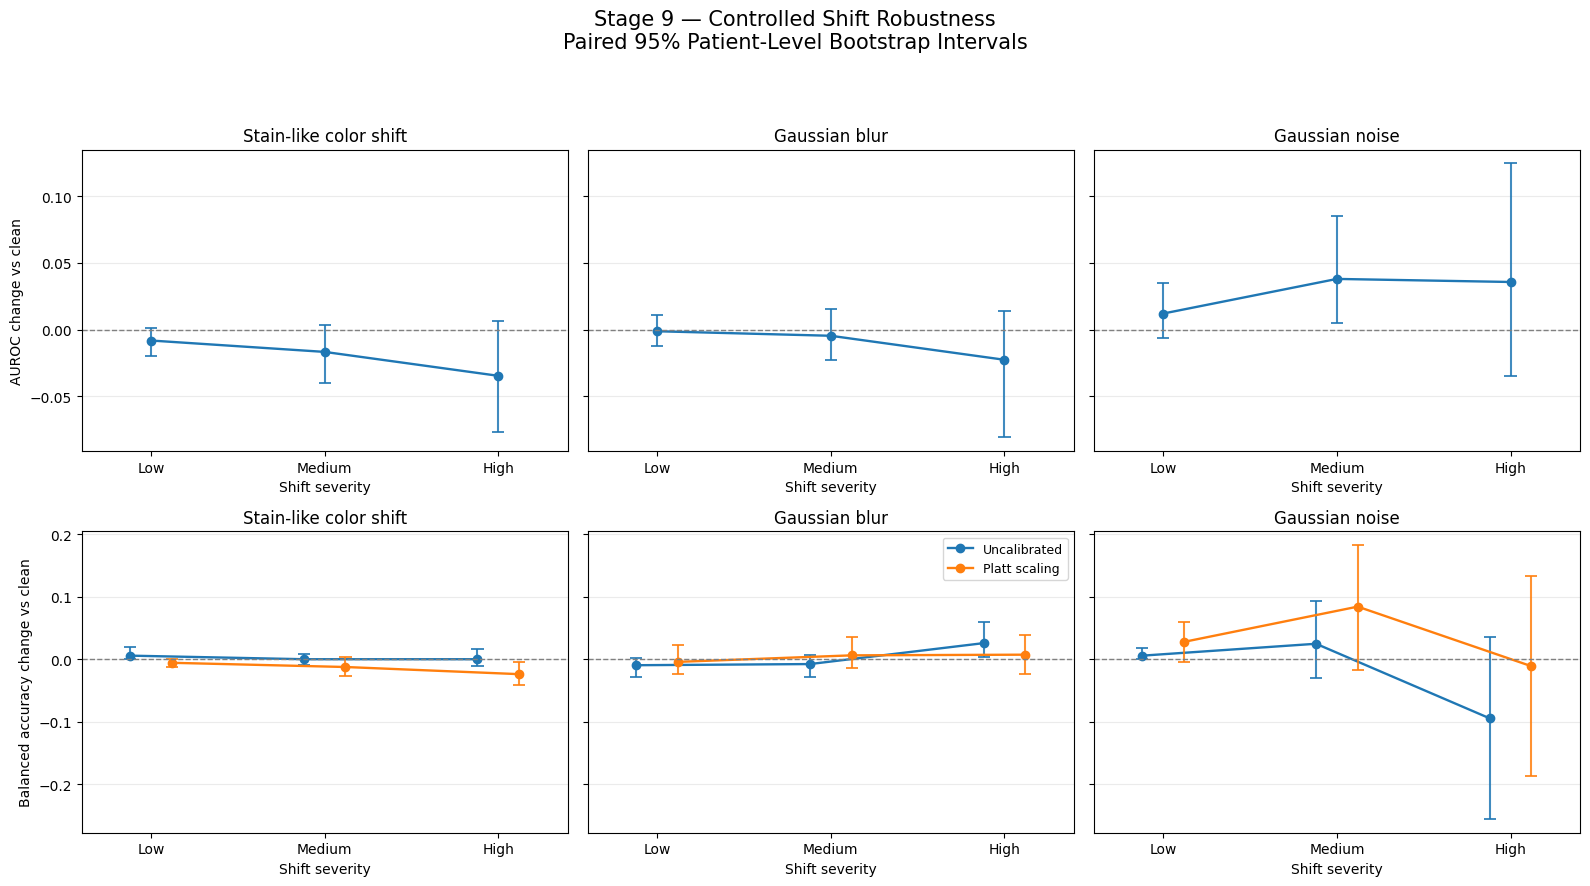

PASS: Discrimination/classification figure saved.


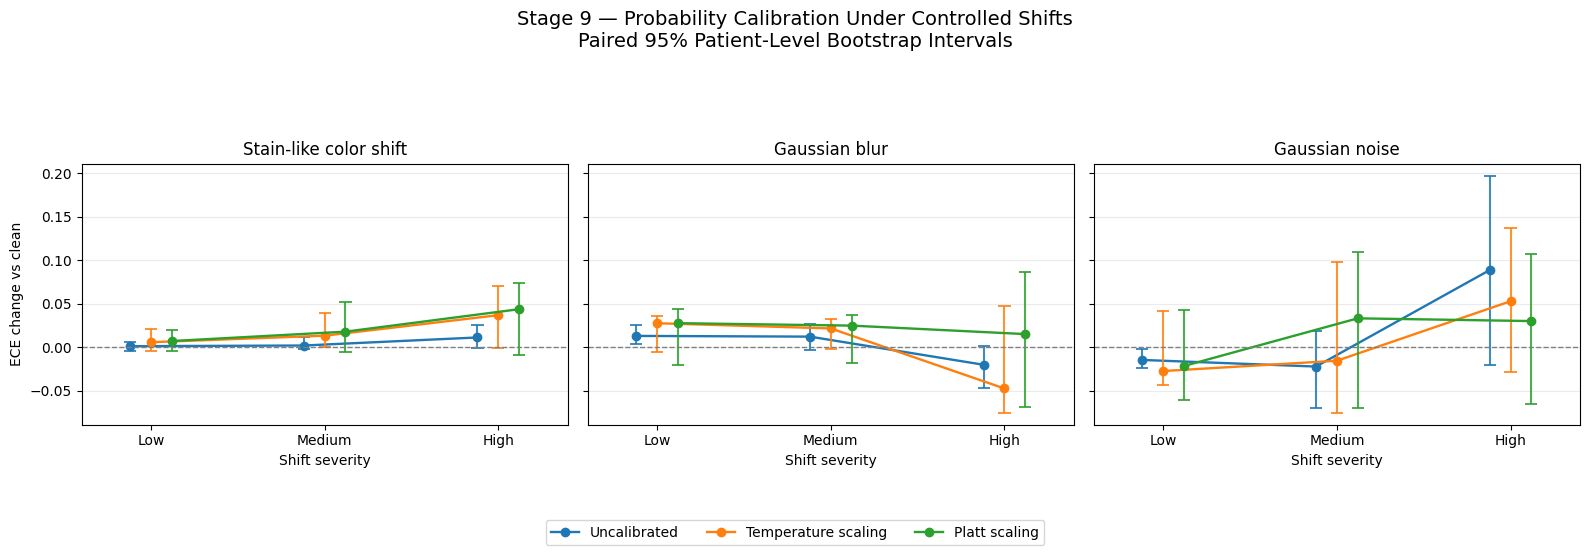

PASS: Calibration robustness figure saved.

KEY CONTROLLED-SHIFT FINDINGS


,condition,delta_auroc,delta_auroc_ci_lower,delta_auroc_ci_upper,platt_minus_uncalibrated_ece,platt_ece_ci_excludes_zero
0,stain_like_od_low,-0.00818,-0.01989,0.00156,-0.08434,False
1,stain_like_od_medium,-0.01672,-0.03993,0.00330,-0.07437,False
2,stain_like_od_high,-0.03467,-0.07646,0.00645,-0.05781,False
3,gaussian_blur_low,-0.00122,-0.01202,0.01088,-0.07564,False
4,gaussian_blur_medium,-0.00462,-0.02304,0.01527,-0.07763,False
5,gaussian_blur_high,-0.02263,-0.08067,0.01361,-0.05504,False
6,gaussian_noise_low,0.01206,-0.00659,0.03500,-0.09719,False
7,gaussian_noise_medium,0.03804,0.00465,0.08492,-0.03490,False
8,gaussian_noise_high,0.03574,-0.03485,0.12484,-0.14884,True


PASS: Medium-noise AUROC interval verified.
PASS: High-noise Platt ECE interval verified.

STAGE 9 — CELL 8 FINAL AUDIT
PASS: All Stage 9 metric files verified.
PASS: All patient-bootstrap outputs verified.
PASS: AUROC robustness figure generated.
PASS: Balanced accuracy changes visualized.
PASS: Three calibration methods visualized.
PASS: ECE robustness figure generated.
PASS: Paired confidence intervals displayed.
PASS: Nine-condition findings summary saved.
PASS: Visualization files and hashes verified.
PASS: Original Stage 9 protocol unchanged.
PASS: Final CNN checkpoint unchanged.
PASS: Both calibration methods unchanged.
PASS: No CNN inference repeated.
PASS: No bootstrap resampling repeated.
PASS: No retraining or recalibration.
PASS: No Test-based method selection.

Figure 1: /content/breast-histology-calibration/results/controlled_shifts/efficientnet_b0/stage9_discrimination_classification_shift_ci.png
Figure 2: /content/breast-histology-calibration/results/controlled_shifts/e

In [ ]:

# ============================================================
# Controlled-Shift Robustness and Calibration Figures
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Verify the locked model, metrics, and bootstrap files
# ------------------------------------------------------------

with open(STAGE9_PROTOCOL_PATH, encoding="utf-8") as f:
    protocol = json.load(f)

with open(
    STAGE9_METRICS_AUDIT_PATH, encoding="utf-8"
) as f:
    metrics_audit = json.load(f)

with open(
    STAGE9_BOOTSTRAP_AUDIT_PATH, encoding="utf-8"
) as f:
    bootstrap_audit = json.load(f)

assert protocol["status"] == "pre_inference_protocol_locked"
assert bootstrap_audit["status"] == "patient_bootstrap_completed"
assert bootstrap_audit["resamples"] == 1000

assert sha256_file(STAGE9_PROTOCOL_PATH) == (
    bootstrap_audit["protocol_sha256"]
)

assert sha256_file(STAGE9_CHECKPOINT_PATH) == (
    EXPECTED_MODEL_SHA256
)

assert sha256_file(PARAMETERS_PATH) == (
    calibration_lock["calibration_parameters_sha256"]
)

assert sha256_file(STAGE9_METRICS_PATH) == (
    metrics_audit["metrics_sha256"]
)

for path in [
    STAGE9_BOOTSTRAP_REPLICATES_PATH,
    STAGE9_BOOTSTRAP_CI_PATH,
    STAGE9_BOOTSTRAP_SHIFT_PATH,
    STAGE9_BOOTSTRAP_CALIBRATION_PATH
]:

    assert path.is_file()

    assert sha256_file(path) == (
        bootstrap_audit["output_sha256"][path.name]
    )

print("=" * 70)
print("STAGE 9 — ROBUSTNESS VISUALIZATION")
print("=" * 70)

print("PASS: Stage 9 protocol verified.")
print("PASS: Original performance metrics verified.")
print("PASS: All bootstrap results verified.")
print("PASS: Model and calibration lock verified.")

# ------------------------------------------------------------
# 2. Load previously saved statistical results
# ------------------------------------------------------------

shift_ci = pd.read_csv(
    STAGE9_BOOTSTRAP_SHIFT_PATH
)

calibration_ci = pd.read_csv(
    STAGE9_BOOTSTRAP_CALIBRATION_PATH
)

metrics = pd.read_csv(
    STAGE9_METRICS_PATH
)

assert len(shift_ci) == 162
assert len(calibration_ci) == 180
assert len(metrics) == 30

assert not shift_ci.duplicated(
    ["condition", "method", "metric"]
).any()

assert not calibration_ci.duplicated(
    ["condition", "method", "comparison_method", "metric"]
).any()

assert shift_ci[
    ["observed_difference", "ci_lower_95", "ci_upper_95"]
].notna().all().all()

assert (
    shift_ci["ci_lower_95"]
    <= shift_ci["ci_upper_95"]
).all()

# ------------------------------------------------------------
# 3. Define original fixed condition ordering
# ------------------------------------------------------------

shift_families = {
    "stain_like_od": "Stain-like color shift",
    "gaussian_blur": "Gaussian blur",
    "gaussian_noise": "Gaussian noise"
}

severity_order = [
    "low",
    "medium",
    "high"
]

methods = [
    "Uncalibrated",
    "Temperature scaling",
    "Platt scaling"
]

assert len(STAGE9_CONDITIONS) == 10

assert set(shift_ci["condition"]) == (
    set(STAGE9_CONDITIONS) - {"clean"}
)

# ------------------------------------------------------------
# 4. Helper for plotting paired confidence intervals
#
# Uses the exact 95% percentile bootstrap intervals
# calculated in Cell 7.
# ------------------------------------------------------------

def plot_shift_metric(
    ax,
    family,
    metric,
    selected_methods
):

    offsets = np.linspace(
        -0.12,
        0.12,
        len(selected_methods)
    ) if len(selected_methods) > 1 else np.array([0.0])

    for method_index, method in enumerate(
        selected_methods
    ):

        rows = shift_ci.loc[
            (shift_ci["shift_family"] == family)
            &
            (shift_ci["method"] == method)
            &
            (shift_ci["metric"] == metric)
        ].copy()

        assert len(rows) == 3

        rows = (
            rows.set_index("shift_severity")
            .loc[severity_order]
        )

        x = np.arange(3, dtype=float) + (
            offsets[method_index]
        )

        observed = rows[
            "observed_difference"
        ].to_numpy(dtype=float)

        lower = rows[
            "ci_lower_95"
        ].to_numpy(dtype=float)

        upper = rows[
            "ci_upper_95"
        ].to_numpy(dtype=float)

        # Use consistent line and interval colors.

        line, = ax.plot(
            x,
            observed,
            marker="o",
            linewidth=1.7,
            markersize=6,
            label=method
        )

        ax.vlines(
            x,
            lower,
            upper,
            colors=line.get_color(),
            linewidth=1.5,
            alpha=0.85
        )

        ax.hlines(
            lower,
            x - 0.035,
            x + 0.035,
            colors=line.get_color(),
            linewidth=1.2
        )

        ax.hlines(
            upper,
            x - 0.035,
            x + 0.035,
            colors=line.get_color(),
            linewidth=1.2
        )

    ax.axhline(
        y=0,
        color="gray",
        linestyle="--",
        linewidth=1
    )

    ax.set_xticks(
        [0, 1, 2],
        ["Low", "Medium", "High"]
    )

    ax.set_xlim(-0.4, 2.4)
    ax.set_title(shift_families[family])
    ax.set_xlabel("Shift severity")

    ax.grid(
        axis="y",
        alpha=0.25
    )


# ------------------------------------------------------------
# 5. Figure 1:
# AUROC and balanced accuracy changes vs clean
# ------------------------------------------------------------

FIGURE1_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_discrimination_classification_shift_ci.png"
)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 9),
    sharey="row"
)

for column, family in enumerate(shift_families):

    plot_shift_metric(
        axes[0, column],
        family,
        "auroc",
        ["Uncalibrated"]
    )

    plot_shift_metric(
        axes[1, column],
        family,
        "balanced_accuracy",
        [
            "Uncalibrated",
            "Platt scaling"
        ]
    )

axes[0, 0].set_ylabel(
    "AUROC change vs clean"
)

axes[1, 0].set_ylabel(
    "Balanced accuracy change vs clean"
)

axes[1, 1].legend(
    loc="best",
    fontsize=9
)

fig.suptitle(
    "Stage 9 — Controlled Shift Robustness\n"
    "Paired 95% Patient-Level Bootstrap Intervals",
    fontsize=15
)

fig.tight_layout(
    rect=[0, 0, 1, 0.93]
)

fig.savefig(
    FIGURE1_PATH,
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

assert FIGURE1_PATH.is_file()
assert FIGURE1_PATH.stat().st_size > 10000

print("PASS: Discrimination/classification figure saved.")

# ------------------------------------------------------------
# 6. Figure 2:
# ECE changes vs clean for all three calibration methods
# ------------------------------------------------------------

FIGURE2_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_calibration_ece_shift_ci.png"
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5.5),
    sharey=True
)

for column, family in enumerate(shift_families):

    plot_shift_metric(
        axes[column],
        family,
        "ece10",
        methods
    )

axes[0].set_ylabel(
    "ECE change vs clean"
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=3,
    fontsize=10
)

fig.suptitle(
    "Stage 9 — Probability Calibration Under Controlled Shifts\n"
    "Paired 95% Patient-Level Bootstrap Intervals",
    fontsize=14
)

fig.tight_layout(
    rect=[0, 0.12, 1, 0.87]
)

fig.savefig(
    FIGURE2_PATH,
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

assert FIGURE2_PATH.is_file()
assert FIGURE2_PATH.stat().st_size > 10000

print("PASS: Calibration robustness figure saved.")

# ------------------------------------------------------------
# 7. Create a concise numerical research summary
#
# Uses saved intervals; does not run new statistical tests.
# ------------------------------------------------------------

shift_lookup = shift_ci.set_index(
    ["condition", "method", "metric"]
)

calibration_lookup = calibration_ci.set_index(
    ["condition", "method", "comparison_method", "metric"]
)

research_records = []

for family in shift_families:

    for severity in severity_order:

        condition = f"{family}_{severity}"

        auc_row = shift_lookup.loc[
            (condition, "Uncalibrated", "auroc")
        ]

        accuracy_row = shift_lookup.loc[
            (condition, "Uncalibrated", "balanced_accuracy")
        ]

        ece_row = shift_lookup.loc[
            (condition, "Uncalibrated", "ece10")
        ]

        platt_row = calibration_lookup.loc[
            (
                condition,
                "Platt scaling",
                "Uncalibrated",
                "ece10"
            )
        ]

        research_records.append({
            "condition": condition,
            "shift_family": family,
            "shift_severity": severity,

            "delta_auroc": float(
                auc_row["observed_difference"]
            ),
            "delta_auroc_ci_lower": float(
                auc_row["ci_lower_95"]
            ),
            "delta_auroc_ci_upper": float(
                auc_row["ci_upper_95"]
            ),

            "delta_balanced_accuracy": float(
                accuracy_row["observed_difference"]
            ),

            "delta_ece_uncalibrated": float(
                ece_row["observed_difference"]
            ),

            "platt_minus_uncalibrated_ece": float(
                platt_row["observed_difference"]
            ),
            "platt_ece_difference_ci_lower": float(
                platt_row["ci_lower_95"]
            ),
            "platt_ece_difference_ci_upper": float(
                platt_row["ci_upper_95"]
            ),

            "auroc_ci_excludes_zero": bool(
                (auc_row["ci_lower_95"] > 0)
                or (auc_row["ci_upper_95"] < 0)
            ),

            "platt_ece_ci_excludes_zero": bool(
                (platt_row["ci_lower_95"] > 0)
                or (platt_row["ci_upper_95"] < 0)
            )
        })

research_summary = pd.DataFrame(
    research_records
)

assert len(research_summary) == 9

RESEARCH_SUMMARY_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_key_robustness_findings.csv"
)

research_summary.to_csv(
    RESEARCH_SUMMARY_PATH,
    index=False,
    float_format="%.17g"
)

assert len(
    pd.read_csv(RESEARCH_SUMMARY_PATH)
) == 9

print("\n" + "=" * 70)
print("KEY CONTROLLED-SHIFT FINDINGS")
print("=" * 70)

display(
    research_summary[
        [
            "condition",
            "delta_auroc",
            "delta_auroc_ci_lower",
            "delta_auroc_ci_upper",
            "platt_minus_uncalibrated_ece",
            "platt_ece_ci_excludes_zero"
        ]
    ].round(5)
)

# ------------------------------------------------------------
# 8. Verify specific important numerical observations
# ------------------------------------------------------------

medium_noise = research_summary.loc[
    research_summary["condition"]
    == "gaussian_noise_medium"
].iloc[0]

assert medium_noise[
    "delta_auroc_ci_lower"
] > 0

high_noise = research_summary.loc[
    research_summary["condition"]
    == "gaussian_noise_high"
].iloc[0]

assert high_noise[
    "platt_ece_difference_ci_upper"
] < 0

# These are exploratory patient-bootstrap intervals,
# not multiple-comparison-adjusted hypothesis tests.

print("PASS: Medium-noise AUROC interval verified.")
print("PASS: High-noise Platt ECE interval verified.")

# ------------------------------------------------------------
# 9. Save visualization and interpretation audit
# ------------------------------------------------------------

STAGE9_VISUALIZATION_AUDIT_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_robustness_visualization_audit.json"
)

visualization_audit = {
    "stage": 9,
    "status": "robustness_visualization_completed",
    "analysis_type":
        "secondary_exploratory_test_sensitivity",
    "test_patients": 16,
    "test_images": 446,
    "shifted_conditions": 9,
    "clean_reference": "Stage8_40x",
    "bootstrap_resamples": 1000,
    "bootstrap_interval_method":
        "95_percentile_patient_cluster",
    "bootstrap_patient_class_stratification": True,
    "paired_patient_draws": True,
    "comparison_definition":
        "shifted_minus_clean",
    "ece_comparison_definition":
        "platt_minus_uncalibrated",
    "calibration_methods": methods,
    "figures_use_saved_bootstrap_results": True,
    "confidence_intervals_adjusted_for_multiple_tests":
        False,
    "protocol_sha256":
        sha256_file(STAGE9_PROTOCOL_PATH),
    "metrics_sha256":
        sha256_file(STAGE9_METRICS_PATH),
    "bootstrap_audit_sha256":
        sha256_file(STAGE9_BOOTSTRAP_AUDIT_PATH),
    "shift_ci_sha256":
        sha256_file(STAGE9_BOOTSTRAP_SHIFT_PATH),
    "calibration_ci_sha256":
        sha256_file(STAGE9_BOOTSTRAP_CALIBRATION_PATH),
    "figure1_sha256":
        sha256_file(FIGURE1_PATH),
    "figure2_sha256":
        sha256_file(FIGURE2_PATH),
    "summary_sha256":
        sha256_file(RESEARCH_SUMMARY_PATH),
    "model_checkpoint_sha256":
        EXPECTED_MODEL_SHA256,
    "calibration_parameters_sha256":
        sha256_file(PARAMETERS_PATH),
    "cnn_inference_performed": False,
    "bootstrap_recomputed": False,
    "cnn_retrained": False,
    "calibrators_refitted": False,
    "test_based_model_selection": False
}

with open(
    STAGE9_VISUALIZATION_AUDIT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        visualization_audit,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 10. Final verification
# ------------------------------------------------------------

assert sha256_file(FIGURE1_PATH) == (
    visualization_audit["figure1_sha256"]
)

assert sha256_file(FIGURE2_PATH) == (
    visualization_audit["figure2_sha256"]
)

assert sha256_file(RESEARCH_SUMMARY_PATH) == (
    visualization_audit["summary_sha256"]
)

assert sha256_file(STAGE9_CHECKPOINT_PATH) == (
    EXPECTED_MODEL_SHA256
)

assert sha256_file(PARAMETERS_PATH) == (
    calibration_lock["calibration_parameters_sha256"]
)

print("\n" + "=" * 70)
print("STAGE 9 — CELL 8 FINAL AUDIT")
print("=" * 70)

print("PASS: All Stage 9 metric files verified.")
print("PASS: All patient-bootstrap outputs verified.")
print("PASS: AUROC robustness figure generated.")
print("PASS: Balanced accuracy changes visualized.")
print("PASS: Three calibration methods visualized.")
print("PASS: ECE robustness figure generated.")
print("PASS: Paired confidence intervals displayed.")
print("PASS: Nine-condition findings summary saved.")
print("PASS: Visualization files and hashes verified.")
print("PASS: Original Stage 9 protocol unchanged.")
print("PASS: Final CNN checkpoint unchanged.")
print("PASS: Both calibration methods unchanged.")
print("PASS: No CNN inference repeated.")
print("PASS: No bootstrap resampling repeated.")
print("PASS: No retraining or recalibration.")
print("PASS: No Test-based method selection.")

print("\nFigure 1:", FIGURE1_PATH)
print("Figure 2:", FIGURE2_PATH)
print("Findings:", RESEARCH_SUMMARY_PATH)
print("Audit:", STAGE9_VISUALIZATION_AUDIT_PATH)


In [ ]:

# ============================================================
# Final Verification and GitHub Results Packaging
# ============================================================

# Reuse imports and variables from Cells 1-8.
# No inference, training, or bootstrap calculations.

# ------------------------------------------------------------
# 1. Verify locked model and calibration parameters
# ------------------------------------------------------------

assert sha256_file(
    STAGE9_CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

with open(STAGE9_PROTOCOL_PATH, encoding="utf-8") as f:
    protocol = json.load(f)

with open(
    STAGE9_IMPLEMENTATION_AUDIT_PATH,
    encoding="utf-8"
) as f:
    implementation_audit = json.load(f)

with open(
    STAGE9_INFERENCE_SETUP_AUDIT_PATH,
    encoding="utf-8"
) as f:
    setup_audit = json.load(f)

with open(
    STAGE9_INFERENCE_AUDIT_PATH,
    encoding="utf-8"
) as f:
    inference_audit = json.load(f)

with open(
    STAGE9_METRICS_AUDIT_PATH,
    encoding="utf-8"
) as f:
    metrics_audit = json.load(f)

with open(
    STAGE9_BOOTSTRAP_AUDIT_PATH,
    encoding="utf-8"
) as f:
    bootstrap_audit = json.load(f)

with open(
    STAGE9_VISUALIZATION_AUDIT_PATH,
    encoding="utf-8"
) as f:
    visualization_audit = json.load(f)

protocol_hash = sha256_file(STAGE9_PROTOCOL_PATH)

assert protocol["status"] == (
    "pre_inference_protocol_locked"
)

assert implementation_audit[
    "protocol_sha256"
] == protocol_hash

assert setup_audit[
    "protocol_sha256"
] == protocol_hash

assert inference_audit[
    "protocol_sha256"
] == protocol_hash

assert metrics_audit[
    "protocol_sha256"
] == protocol_hash

assert bootstrap_audit[
    "protocol_sha256"
] == protocol_hash

assert visualization_audit[
    "protocol_sha256"
] == protocol_hash

assert inference_audit["status"] == (
    "all_shifted_inference_completed"
)

assert bootstrap_audit["status"] == (
    "patient_bootstrap_completed"
)

assert visualization_audit["status"] == (
    "robustness_visualization_completed"
)

print("=" * 70)
print("STAGE 9 — FINAL RESEARCH VERIFICATION")
print("=" * 70)

print("PASS: Final CNN checkpoint verified.")
print("PASS: Both locked calibrators verified.")
print("PASS: Original experimental protocol unchanged.")
print("PASS: All Stage 9 audit records verified.")

# ------------------------------------------------------------
# 2. Verify provenance across experimental stages
# ------------------------------------------------------------

assert sha256_file(
    TEST40_MANIFEST_PATH
) == protocol["clean_test_manifest_sha256"]

assert sha256_file(
    TEST40_PREDICTIONS_PATH
) == protocol["clean_test_predictions_sha256"]

assert inference_audit[
    "implementation_audit_sha256"
] == sha256_file(
    STAGE9_IMPLEMENTATION_AUDIT_PATH
)

assert inference_audit[
    "setup_audit_sha256"
] == sha256_file(
    STAGE9_INFERENCE_SETUP_AUDIT_PATH
)

assert metrics_audit[
    "inference_audit_sha256"
] == sha256_file(
    STAGE9_INFERENCE_AUDIT_PATH
)

assert bootstrap_audit[
    "original_metrics_sha256"
] == sha256_file(
    STAGE9_METRICS_PATH
)

assert visualization_audit[
    "bootstrap_audit_sha256"
] == sha256_file(
    STAGE9_BOOTSTRAP_AUDIT_PATH
)

assert visualization_audit[
    "metrics_sha256"
] == sha256_file(
    STAGE9_METRICS_PATH
)

print("PASS: Stage 8 clean reference verified.")
print("PASS: Stage 9 provenance chain verified.")

# ------------------------------------------------------------
# 3. Verify all nine per-condition inference outputs
# ------------------------------------------------------------

condition_ids = [
    condition
    for condition in STAGE9_CONDITIONS
    if condition != "clean"
]

assert len(condition_ids) == 9

for condition_id in condition_ids:

    patch_path = (
        STAGE9_RESULTS_DIR /
        f"stage9_{condition_id}_patch_predictions.csv"
    )

    image_path = (
        STAGE9_RESULTS_DIR /
        f"stage9_{condition_id}_image_predictions.csv"
    )

    audit_path = (
        STAGE9_RESULTS_DIR /
        f"stage9_{condition_id}_inference_audit.json"
    )

    assert all(
        path.is_file()
        for path in [
            patch_path,
            image_path,
            audit_path
        ]
    )

    with open(audit_path, encoding="utf-8") as f:
        condition_audit = json.load(f)

    assert condition_audit["condition"] == condition_id

    assert condition_audit[
        "checkpoint_sha256"
    ] == EXPECTED_MODEL_SHA256

    assert condition_audit[
        "protocol_sha256"
    ] == protocol_hash

    assert sha256_file(
        patch_path
    ) == condition_audit[
        "patch_predictions_sha256"
    ]

    assert sha256_file(
        image_path
    ) == condition_audit[
        "image_predictions_sha256"
    ]

    combined_hashes = inference_audit[
        "condition_output_sha256"
    ][condition_id]

    assert combined_hashes[
        "patch_predictions"
    ] == sha256_file(patch_path)

    assert combined_hashes[
        "image_predictions"
    ] == sha256_file(image_path)

    assert combined_hashes[
        "inference_audit"
    ] == sha256_file(audit_path)

    assert condition_audit[
        "calibrators_refitted"
    ] is False

    assert len(pd.read_csv(patch_path)) == 7087
    assert len(pd.read_csv(image_path)) == 446

    print(f"PASS: {condition_id} verified.")

# ------------------------------------------------------------
# 4. Verify combined predictions and statistical analysis
# ------------------------------------------------------------

assert sha256_file(
    STAGE9_ALL_SHIFTED_IMAGE_PATH
) == inference_audit[
    "combined_predictions_sha256"
]

assert sha256_file(
    STAGE9_METRICS_PATH
) == metrics_audit["metrics_sha256"]

assert sha256_file(
    STAGE9_DIFFERENCES_PATH
) == metrics_audit["differences_sha256"]

assert sha256_file(
    FIGURE1_PATH
) == visualization_audit["figure1_sha256"]

assert sha256_file(
    FIGURE2_PATH
) == visualization_audit["figure2_sha256"]

assert sha256_file(
    RESEARCH_SUMMARY_PATH
) == visualization_audit["summary_sha256"]

bootstrap_paths = [
    STAGE9_BOOTSTRAP_REPLICATES_PATH,
    STAGE9_BOOTSTRAP_CI_PATH,
    STAGE9_BOOTSTRAP_SHIFT_PATH,
    STAGE9_BOOTSTRAP_CALIBRATION_PATH
]

for path in bootstrap_paths:

    assert path.is_file()

    assert sha256_file(path) == bootstrap_audit[
        "output_sha256"
    ][path.name]

assert len(pd.read_csv(
    STAGE9_ALL_SHIFTED_IMAGE_PATH
)) == 4014

assert len(pd.read_csv(STAGE9_METRICS_PATH)) == 30

assert len(pd.read_csv(
    STAGE9_DIFFERENCES_PATH
)) == 27

assert len(pd.read_csv(
    STAGE9_BOOTSTRAP_REPLICATES_PATH
)) == 30000

assert len(pd.read_csv(
    STAGE9_BOOTSTRAP_CI_PATH
)) == 180

assert len(pd.read_csv(
    STAGE9_BOOTSTRAP_SHIFT_PATH
)) == 162

assert len(pd.read_csv(
    STAGE9_BOOTSTRAP_CALIBRATION_PATH
)) == 180

assert len(pd.read_csv(
    RESEARCH_SUMMARY_PATH
)) == 9

print("\nPASS: All inference predictions verified.")
print("PASS: All performance metrics verified.")
print("PASS: All 30,000 bootstrap result rows verified.")
print("PASS: Both robustness figures verified.")

# ------------------------------------------------------------
# 5. Generate complete Stage 9 results inventory
# ------------------------------------------------------------

base_filenames = [
    "stage9_pre_inference_protocol_lock.json",
    "stage9_shift_implementation_validation.csv",
    "stage9_shift_implementation_audit.json",
    "stage9_shift_preview_benign.png",
    "stage9_shift_preview_malignant.png",
    "stage9_inference_setup_audit.json",
    "stage9_all_shifted_image_predictions.csv",
    "stage9_shifted_inference_combined_audit.json",
    "stage9_performance_metrics_all_conditions.csv",
    "stage9_shift_vs_clean_metric_differences.csv",
    "stage9_performance_evaluation_audit.json",
    "stage9_patient_bootstrap_1000_replicates.csv",
    "stage9_patient_bootstrap_metric_ci.csv",
    "stage9_patient_bootstrap_shift_vs_clean_ci.csv",
    "stage9_patient_bootstrap_calibration_differences.csv",
    "stage9_patient_bootstrap_audit.json",
    "stage9_discrimination_classification_shift_ci.png",
    "stage9_calibration_ece_shift_ci.png",
    "stage9_key_robustness_findings.csv",
    "stage9_robustness_visualization_audit.json"
]

assert len(base_filenames) == 20

required_files = [
    STAGE9_RESULTS_DIR / name
    for name in base_filenames
]

for condition_id in condition_ids:

    required_files.extend([
        STAGE9_RESULTS_DIR /
        f"stage9_{condition_id}_patch_predictions.csv",

        STAGE9_RESULTS_DIR /
        f"stage9_{condition_id}_image_predictions.csv",

        STAGE9_RESULTS_DIR /
        f"stage9_{condition_id}_inference_audit.json"
    ])

required_files = sorted(
    [path.resolve() for path in required_files],
    key=lambda path: str(path)
)

assert len(required_files) == 47

assert len(set(required_files)) == 47

assert all(
    path.is_file()
    for path in required_files
)

assert all(
    path.is_relative_to(REPO_ROOT.resolve())
    for path in required_files
)

assert not any(
    path.suffix.lower() in {".pt", ".pth", ".ckpt"}
    for path in required_files
)

print("PASS: All 47 original Stage 9 files located.")
print("PASS: No CNN checkpoint included.")

# ------------------------------------------------------------
# 6. Prepare verified numerical summary for the README
# ------------------------------------------------------------

metrics_df = pd.read_csv(STAGE9_METRICS_PATH)

shift_ci_df = pd.read_csv(
    STAGE9_BOOTSTRAP_SHIFT_PATH
)

calibration_ci_df = pd.read_csv(
    STAGE9_BOOTSTRAP_CALIBRATION_PATH
)

metrics_index = metrics_df.set_index(
    ["condition", "method"]
)

readme_table = [
    "| Condition | AUROC | Balanced accuracy | "
    "Raw ECE | Temperature ECE | Platt ECE |",
    "|---|---:|---:|---:|---:|---:|"
]

for condition in STAGE9_CONDITIONS:

    raw = metrics_index.loc[
        (condition, "Uncalibrated")
    ]

    temperature = metrics_index.loc[
        (condition, "Temperature scaling")
    ]

    platt = metrics_index.loc[
        (condition, "Platt scaling")
    ]

    readme_table.append(
        f"| {condition} "
        f"| {raw['auroc']:.4f} "
        f"| {raw['balanced_accuracy']:.4f} "
        f"| {raw['ece10']:.4f} "
        f"| {temperature['ece10']:.4f} "
        f"| {platt['ece10']:.4f} |"
    )

metrics_markdown = "\n".join(readme_table)

def get_unique_result(df, **filters):

    mask = np.ones(len(df), dtype=bool)

    for column, value in filters.items():
        mask &= df[column].eq(value).to_numpy()

    rows = df.loc[mask]

    assert len(rows) == 1

    return rows.iloc[0]


medium_noise_auc = get_unique_result(
    shift_ci_df,
    condition="gaussian_noise_medium",
    method="Uncalibrated",
    metric="auroc"
)

high_noise_platt_ece = get_unique_result(
    calibration_ci_df,
    condition="gaussian_noise_high",
    method="Platt scaling",
    comparison_method="Uncalibrated",
    metric="ece10"
)

high_color_auc = get_unique_result(
    shift_ci_df,
    condition="stain_like_od_high",
    method="Uncalibrated",
    metric="auroc"
)

assert medium_noise_auc["ci_lower_95"] > 0

assert high_noise_platt_ece["ci_upper_95"] < 0

# ------------------------------------------------------------
# 7. Generate research methodology README
# ------------------------------------------------------------

STAGE9_README_PATH = (
    STAGE9_RESULTS_DIR /
    "STAGE9_RESULTS_README.md"
)

readme_text = f"""# Stage 9 — Controlled Distribution Shift Evaluation

## Research objective

Evaluate how controlled color, blur, and noise
perturbations affect discrimination, classification,
and confidence calibration of the final frozen
EfficientNet-B0 breast histopathology classifier.

## Evaluation cohort

- Dataset: BreaKHis
- Partition: Original independent Test
- Magnification: 40x
- Independent patients: 16
- Benign patients: 5
- Malignant patients: 11
- Images per condition: 446
- Patches per condition: 7,087
- Shifted conditions: 9
- Original clean reference conditions: 1
- Total shifted patch evaluations: 63,783
- Total shifted image predictions: 4,014

The clean reference was reused from Stage 8.

## Frozen model

- Architecture: EfficientNet-B0
- Checkpoint: Final Epoch 5
- Checkpoint SHA-256: {EXPECTED_MODEL_SHA256}
- Patch size: 224 x 224 pixels
- Aggregation: arithmetic mean of patch logits
- Classification threshold: 0.5

No CNN weights were changed during Stage 9.

## Controlled perturbations

### Stain-like color shift

Fixed RGB optical-density channel scaling.

Severity parameters:

- Low: 0.05
- Medium: 0.10
- High: 0.20

This is a controlled stain-like color perturbation.
It is NOT a validated physical H&E stain
transformation or stain-separation method.

### Gaussian blur

Spatial Gaussian blur, measured in patch pixels.

- Low: sigma 0.5
- Medium: sigma 1.0
- High: sigma 2.0

### Gaussian noise

Additive RGB Gaussian noise on [0, 1] pixels.

- Low: sigma 0.02
- Medium: sigma 0.05
- High: sigma 0.10

The noise seed was fixed to 631.
Noise was deterministic for each original patch.

The same underlying noise realization was scaled
for all three severity levels.

## Preprocessing controls

Original Stage 8 tissue-selected patches were reused.

Original source image resizing, patch coordinates,
and patch selection were preserved.

Perturbations were applied after original patch
extraction and before ImageNet normalization.

This isolates changes in pixel appearance from
changes in patch sampling.

## Calibration

Temperature scaling:

T = {LOCKED_TEMPERATURE}

Platt scaling:

slope = {LOCKED_PLATT_SLOPE}
intercept = {LOCKED_PLATT_INTERCEPT}

Both methods were fitted before Test evaluation.
They were not refitted on shifted images.

## Evaluation metrics

- AUROC
- Average precision
- Balanced accuracy
- Sensitivity and specificity
- Expected Calibration Error, 10 equal-width bins
- Brier score
- Binary negative log-likelihood

All evaluations use image-level predictions.

## Descriptive results

{metrics_markdown}

## Patient-level statistical analysis

- Bootstrap resamples: 1,000
- Random seed: 631
- Sampling unit: patient
- Sampling with replacement
- Stratified by patient diagnosis
- Five benign and eleven malignant patient draws
  per bootstrap replicate
- Same draws for all methods and conditions
- Repeated patient draws preserve all their images
- Intervals: 95% percentile bootstrap

Bootstrap comparisons include:

1. Shifted condition minus clean reference
2. Calibrated method minus comparison method

## Key findings

High stain-like color shift produced an observed
AUROC change of
{high_color_auc['observed_difference']:.4f},
95% CI
[{high_color_auc['ci_lower_95']:.4f},
{high_color_auc['ci_upper_95']:.4f}].

Medium Gaussian noise produced an observed
AUROC change of
{medium_noise_auc['observed_difference']:+.4f},
95% CI
[{medium_noise_auc['ci_lower_95']:+.4f},
{medium_noise_auc['ci_upper_95']:+.4f}].

At high noise, Platt scaling minus uncalibrated
ECE was
{high_noise_platt_ece['observed_difference']:+.4f},
95% CI
[{high_noise_platt_ece['ci_lower_95']:+.4f},
{high_noise_platt_ece['ci_upper_95']:+.4f}].

Calibration can improve probability quality
without changing discrimination.

Different shift types affect ranking,
classification thresholds, and probability
calibration differently.

## Statistical limitations

This is a secondary exploratory sensitivity
analysis on previously evaluated Test patients.

There are only 16 independent Test patients.

Confidence intervals are patient-stratified
percentile bootstrap intervals.

The many related comparisons were not adjusted
for multiple hypothesis testing.

Intervals excluding zero should not be treated
as definitive confirmatory evidence.

The selected perturbations are synthetic.
They do not establish robustness to all real
laboratory or acquisition shifts.

The model is not validated for clinical use.

## Reproducibility

The Stage 9 outputs contain:

- Locked experimental protocol
- Perturbation validation and image previews
- Per-condition patch and image predictions
- Inference integrity audits
- Performance and calibration metrics
- Patient-level bootstrap results
- Shift-versus-clean comparisons
- Calibration-method comparisons
- Robustness figures
- SHA-256 inventory

The clean reference is stored in the
Stage 8 results directory.

The Stage 9 notebook should be committed
separately under Notebooks/.

Original dataset images and CNN weights are
not included in this results package.

No CNN retraining, calibrator refitting,
or Test-based severity tuning was performed.
"""

STAGE9_README_PATH.write_text(
    readme_text,
    encoding="utf-8"
)

assert STAGE9_README_PATH.is_file()

print("PASS: Stage 9 methodology README generated.")

# ------------------------------------------------------------
# 8. Generate SHA-256 package inventory
# ------------------------------------------------------------

package_source_files = sorted(
    required_files + [
        STAGE9_README_PATH.resolve()
    ],
    key=lambda path: str(path)
)

assert len(package_source_files) == 48

inventory_records = []

for path in package_source_files:

    inventory_records.append({
        "relative_path": str(
            path.relative_to(REPO_ROOT.resolve())
        ),
        "sha256": sha256_file(path),
        "size_bytes": path.stat().st_size
    })

file_inventory = pd.DataFrame(
    inventory_records
)

STAGE9_FILE_INVENTORY_PATH = (
    STAGE9_RESULTS_DIR /
    "stage9_package_file_inventory.csv"
)

file_inventory.to_csv(
    STAGE9_FILE_INVENTORY_PATH,
    index=False
)

assert len(file_inventory) == 48

print("PASS: All 48 research files inventoried.")

# ------------------------------------------------------------
# 9. Build final GitHub-ready results ZIP
# ------------------------------------------------------------

STAGE9_COMPLETE_BACKUP_PATH = Path(
    "/content/"
    "CIS631_Stage9_Complete_Results_For_GitHub.zip"
)

package_files = (
    package_source_files
    + [STAGE9_FILE_INVENTORY_PATH.resolve()]
)

assert len(package_files) == 49

temporary_zip = (
    STAGE9_COMPLETE_BACKUP_PATH.with_suffix(
        ".zip.tmp"
    )
)

with zipfile.ZipFile(
    temporary_zip,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6
) as archive:

    for path in package_files:

        archive.write(
            path,
            arcname=str(
                path.relative_to(REPO_ROOT.resolve())
            )
        )

temporary_zip.replace(
    STAGE9_COMPLETE_BACKUP_PATH
)

# ------------------------------------------------------------
# 10. Independently verify ZIP contents
# ------------------------------------------------------------

with zipfile.ZipFile(
    STAGE9_COMPLETE_BACKUP_PATH,
    "r"
) as archive:

    assert archive.testzip() is None

    archived_names = set(
        archive.namelist()
    )

    expected_names = {
        str(
            path.relative_to(REPO_ROOT.resolve())
        )
        for path in package_files
    }

    assert archived_names == expected_names

    assert len(archived_names) == 49

    # Independently verify archived bytes
    # against the SHA-256 inventory.

    for _, record in file_inventory.iterrows():

        archived_bytes = archive.read(
            record["relative_path"]
        )

        archived_hash = hashlib.sha256(
            archived_bytes
        ).hexdigest()

        assert archived_hash == record["sha256"]

        assert len(archived_bytes) == int(
            record["size_bytes"]
        )

    # Ensure no trained model weights are packaged.

    assert not any(
        name.lower().endswith(
            (".pt", ".pth", ".ckpt")
        )
        for name in archived_names
    )

    # All Stage 9 results must retain
    # their original repository structure.

    assert all(
        name.startswith(
            "results/controlled_shifts/efficientnet_b0/"
        )
        for name in archived_names
    )

print("PASS: Final ZIP integrity verified.")
print("PASS: All 49 archived files accounted for.")
print("PASS: Archived SHA-256 hashes verified.")
print("PASS: GitHub directory structure preserved.")
print("PASS: No CNN weights included.")

# ------------------------------------------------------------
# 11. Final Stage 9 completion audit
# ------------------------------------------------------------

assert sha256_file(
    STAGE9_CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

assert sha256_file(
    STAGE9_PROTOCOL_PATH
) == protocol_hash

assert sha256_file(
    STAGE9_ALL_SHIFTED_IMAGE_PATH
) == inference_audit[
    "combined_predictions_sha256"
]

assert sha256_file(
    STAGE9_METRICS_PATH
) == metrics_audit["metrics_sha256"]

print("\n" + "=" * 70)
print("STAGE 9 — FINAL COMPLETION AUDIT")
print("=" * 70)

print("PASS: Independent Test cohort verified.")
print("PASS: Original 40x clean reference preserved.")
print("PASS: Nine controlled-shift conditions evaluated.")
print("PASS: All 63,783 shifted patch predictions saved.")
print("PASS: All 4,014 shifted image predictions saved.")
print("PASS: All 30 performance evaluation rows verified.")
print("PASS: Shift-versus-clean differences preserved.")
print("PASS: 1,000 patient-level bootstrap resamples saved.")
print("PASS: All confidence interval outputs verified.")
print("PASS: Paired calibration comparisons preserved.")
print("PASS: Robustness and calibration figures saved.")
print("PASS: Original perturbation previews preserved.")
print("PASS: Stage 9 methodology documented.")
print("PASS: All source-file SHA-256 hashes verified.")
print("PASS: GitHub-ready results ZIP created.")
print("PASS: All 49 ZIP entries verified.")
print("PASS: Original Stage 9 protocol unchanged.")
print("PASS: Final CNN checkpoint unchanged.")
print("PASS: Both calibration methods unchanged.")
print("PASS: No CNN retraining or calibrator refitting.")
print("PASS: No Test-based model or severity selection.")

print("\n" + "=" * 70)
print("STAGE 9 — GITHUB PACKAGE")
print("=" * 70)

print("Package:", STAGE9_COMPLETE_BACKUP_PATH)

print(
    "ZIP size (MB):",
    round(
        STAGE9_COMPLETE_BACKUP_PATH.stat().st_size
        / (1024 ** 2),
        2
    )
)

print("Total ZIP files:", len(package_files))

# Flag individual files too large for typical
# GitHub browser uploads.

large_files = file_inventory.loc[
    file_inventory["size_bytes"]
    > 25 * 1024 * 1024
]

if not large_files.empty:

    print(
        "\nWARNING: Files larger than 25 MB detected."
    )

    display(
        large_files[
            ["relative_path", "size_bytes"]
        ]
    )

print("\nDownloading completed Stage 9 results...")

files.download(
    str(STAGE9_COMPLETE_BACKUP_PATH)
)


STAGE 9 — FINAL RESEARCH VERIFICATION
PASS: Final CNN checkpoint verified.
PASS: Both locked calibrators verified.
PASS: Original experimental protocol unchanged.
PASS: All Stage 9 audit records verified.
PASS: Stage 8 clean reference verified.
PASS: Stage 9 provenance chain verified.
PASS: stain_like_od_low verified.
PASS: stain_like_od_medium verified.
PASS: stain_like_od_high verified.
PASS: gaussian_blur_low verified.
PASS: gaussian_blur_medium verified.
PASS: gaussian_blur_high verified.
PASS: gaussian_noise_low verified.
PASS: gaussian_noise_medium verified.
PASS: gaussian_noise_high verified.

PASS: All inference predictions verified.
PASS: All performance metrics verified.
PASS: All 30,000 bootstrap result rows verified.
PASS: Both robustness figures verified.
PASS: All 47 original Stage 9 files located.
PASS: No CNN checkpoint included.
PASS: Stage 9 methodology README generated.
PASS: All 48 research files inventoried.
PASS: Final ZIP integrity verified.
PASS: All 49 archived

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>